# Notebook 03 — Análise estatística: as features são normais? O log ajuda? (coleta intercalada NOVOS_2.0)

**O que buscamos aqui:** os Notebooks 01 e 02 mostraram *o que muda* entre o normal e cada anomalia. Agora fazemos uma pergunta de outro tipo: **qual é o formato das distribuições das features, e o quanto as janelas dependem umas das outras?** Isso decide como tratar os dados antes do K-Means (Notebook 04) e da classificação (Notebook 05). Seis perguntas:

1. As 109 features seguem uma **distribuição normal** (o "sino" simétrico)? Quais sim, quais não?
2. **Juntar os 5 lotes de normal** muda o formato? (Importa para o detector só de normal do Notebook 06.)
3. As que não seguem são **muito tortas** ou só um pouco? Como isso aparece **a olho**, em histogramas e QQ-plots?
4. As janelas de uma gravação são **independentes**? A dependência vem de tendência (aquecimento) ou do ciclo da oscilação?
5. **Até quantas janelas** a dependência vai? A guarda de 5 s escolhida para os blocos do Notebook 05 é suficiente?
6. A **transformação logarítmica** deixa as features mais normais? Em quais?

| Passo | O que fazemos | O que buscamos |
| --- | --- | --- |
| 1 | Configurar parâmetros | A ordem da sessão e os limites estatísticos |
| 2 | Carregar as bases | As mesmas bases dos Notebooks 01 e 02, cada gravação com o seu bloco da sessão |
| 3 | Cortar em janelas e calcular as 109 features | A mesma tabela do Notebook 02 |
| 4 | Explicar as escolhas estatísticas | Entender o que será testado e por quê |
| 5 | Shapiro-Wilk com correção para muitos testes | Quantas features parecem normais, em cada gravação |
| 5.2 | Os 5 normais juntos | O que acontece com o formato quando os lotes se misturam |
| 6 | Assimetria, histogramas e QQ-plots | O quanto e como elas se afastam da normal |
| 7 | Autocorrelação entre janelas | O quanto os p-valores merecem confiança, e de onde vem a dependência |
| 7.4 | Dependência por distância (lag) | Se a guarda dos blocos do Notebook 05 é suficiente |
| 8 | Transformação logarítmica | O log aproximou as features da normal? |
| 9 | Features que não aceitam log (curtose) | Alternativa para elas |
| Resumo | Tabela e decisões | O que levar para os Notebooks 04 e 05 |

## O que muda em relação ao Notebook 03 da coleta anterior

* **Cada gravação é um grupo.** Na coleta anterior havia uma gravação por condição e velocidade, com cerca de 125 janelas. Aqui há **27 gravações** (5 lotes de normal e 4 anomalias, nas 3 velocidades), com **33 a 43 janelas** cada. Os testes são feitos **em cada gravação** (por exemplo, `1. N1` na Vel 1), para não misturar lotes.
* **Menos janelas, testes menos sensíveis.** Com cerca de 37 janelas, o Shapiro-Wilk tem menos poder: ele rejeita a normalidade com mais dificuldade do que com 125. **As porcentagens de "normais" não são diretamente comparáveis** com as da coleta anterior.
* **O aquecimento está entre os lotes, não dentro das gravações** (Notebooks 01 e 02). Isso muda a leitura da autocorrelação (Passo 7) e torna o Passo 5.2 importante: juntar os lotes pode criar distribuições com vários "montes".
* **Corte do começo e do fim:** os primeiros e os últimos 5 s de cada base são descartados, como nos Notebooks 01 e 02.

## Como usar

1. Use a mesma pasta e a mesma `ORDEM_SESSAO` dos Notebooks 01 e 02.
2. Rode as células em ordem. **Em cada passo, leia primeiro o texto e depois os resultados**: a parte estatística é fácil de errar quando se olha só o número.

## Glossário rápido (volte aqui sempre que travar)

* **Distribuição normal:** o "sino". A maioria dos valores fica perto da média, e os extremos são raros e simétricos dos dois lados.
* **Teste de normalidade (Shapiro-Wilk):** parte da hipótese de que os dados **são** normais e pergunta: *"se fossem mesmo normais, seria muito raro eu ver um formato tão diferente do sino?"*
* **p-valor:** a resposta dessa pergunta. **p pequeno (abaixo de 0,05)** quer dizer "seria muito raro": rejeitamos a normalidade. **p grande** quer dizer "não há evidência contra": a feature *pode* ser normal (isso **não prova** que seja).
* **W:** a nota do teste, de 0 a 1. **1 = sino perfeito.** Quanto menor, mais distante.
* **Assimetria (skewness):** 0 = simétrica. **Positiva:** cauda comprida para a direita. **Negativa:** cauda para a esquerda.
* **QQ-plot:** compara os seus dados com uma normal ideal. **Pontos sobre a reta = normal.**
* **Correção para muitos testes (BH):** quando se faz 109 testes de uma vez, alguns dão p < 0,05 só por sorte. A correção ajusta isso (Passo 4). O p ajustado se chama **q**.
* **Log:** troca cada valor pelo seu logaritmo. "Espreme" valores muito grandes e deixa distribuições com cauda comprida mais simétricas.
* **Autocorrelação de lag k:** a correlação de uma feature com ela mesma **k janelas depois**, dentro da mesma gravação.

**Convenção das células:** cada função fica numa célula e a sua execução fica na célula seguinte.

## Passo 1 — Configuração

**O que buscamos:** concentrar num só lugar tudo o que muda de um experimento para outro. As três escolhas **estatísticas** estão no bloco "ESTATÍSTICA" e cada uma é explicada no Passo 4.

In [1]:
from pathlib import Path
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
from scipy.stats import kurtosis, shapiro, skew, norm, yeojohnson
from IPython.display import display

plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.linestyle": "--", "grid.alpha": 0.4})

In [2]:
# ----------------------------------------------------------------------
# ONDE ESTÃO OS DADOS (a mesma pasta dos Notebooks 01 e 02)
# ----------------------------------------------------------------------
PASTA_BASES = Path(r"C:\Users\santo\OneDrive\Área de Trabalho\TCC\DADOS\NOVOS_DADOS\NOVOS_2.0")
BUSCAR_EM_SUBPASTAS = True        # True = lê também os CSVs dentro das subpastas (NORMAL_LOTE_1, CALCO, ...)
DESCARTAR_INICIO_S = 5            # segundos descartados no começo de cada base (Notebook 01, Passo 4.1)
DESCARTAR_FIM_S = 5               # segundos descartados no fim de cada base

# ----------------------------------------------------------------------
# ORDEM DA SESSÃO (a mesma dos Notebooks 01 e 02)
# ATENÇÃO: a ordem entre fita_1g e fita_05g NÃO foi anotada; aqui está assumida (1 g antes de 0,5 g).
# ----------------------------------------------------------------------
ORDEM_SESSAO = [
    "ventilador_normal", "calco", "ventilador_normal", "fita_1g", "ventilador_normal",
    "fita_05g", "ventilador_normal", "papel", "ventilador_normal",
]
CONDICAO_NORMAL = "ventilador_normal"
CONDICOES_REFERENCIA = [CONDICAO_NORMAL]       # nos gráficos, "referência" = os 5 lotes de normal juntos
CONDICOES_COMPARADAS = None                    # None = todas as outras condições da pasta, na ordem da sessão

# ----------------------------------------------------------------------
# COMO OS DADOS FORAM COLETADOS
# ----------------------------------------------------------------------
TAXA_AMOSTRAGEM_HZ = 1000
EIXOS = ["x", "y", "z"]
UNIDADE = "m/s²"

# ----------------------------------------------------------------------
# JANELAS E FEATURES (a mesma receita do Notebook 02: 109 features)
# ----------------------------------------------------------------------
JANELA_S = 5                      # janela de 5 s, sem sobreposição
FAIXA_FFT_HZ = (5, 305)           # faixas de 10 Hz de 5 a 305 Hz
LARGURA_FAIXA_HZ = 10
FAIXA_BUSCA_1X_HZ = (8, 30)       # faixa onde procuramos o pico de rotação
DESVIO_MAX_1X_HZ = 2.0            # o 1X só pode ficar a até esta distância da rotação típica da base
N_HARMONICAS = 3                  # mede 1X, 2X e 3X
TOLERANCIA_HARMONICA_HZ = 0.6     # a amplitude de kX é o maior pico a até esta distância de k vezes o 1X

# ----------------------------------------------------------------------
# ESTATÍSTICA (explicadas no Passo 4)
# ----------------------------------------------------------------------
ALFA = 0.05                       # nível de significância: p (ou q) abaixo disto rejeita a normalidade
LIMITE_ASSIMETRIA = 1.0           # |assimetria| acima disto = distribuição claramente torta
MIN_JANELAS = 20                  # com menos janelas que isto o teste não é feito
LIMITE_Z_ROBUSTO = 8              # uma feature é "extrema" numa janela se passa disto em desvios robustos (MAD)
MIN_FEATURES_ATIPICAS = 10        # uma janela é "atípica" se tem pelo menos este número de features extremas

# ----------------------------------------------------------------------
# CICLO LENTO DA VIBRAÇÃO (Passo 7.2)
# ----------------------------------------------------------------------
EIXO_MODULACAO = "z"              # eixo cuja intensidade é acompanhada ao longo do tempo
BLOCO_MODULACAO_S = 0.25          # a intensidade (desvio padrão) é medida a cada bloco deste tamanho
FAIXA_PERIODO_MODULACAO_S = (3, 30)   # procuramos ciclos de 3 s a 30 s
BASES_EXEMPLO_CICLO = [           # bases mostradas no gráfico do ciclo (a tabela tem todas)
    "ventilador_normal_vel_1_lote_1", "ventilador_normal_vel_2_lote_1", "ventilador_normal_vel_3_lote_1",
    "fita_05g_vel_3",
]

# ----------------------------------------------------------------------
# TENDÊNCIA LENTA — Passo 7.3
# ----------------------------------------------------------------------
JANELAS_TENDENCIA = 9             # mediana móvel de 9 janelas (45 s): cobre pelo menos 2,5 ciclos da oscilação em qualquer velocidade
BASE_EXEMPLO_TENDENCIA = "papel_vel_3"   # base do gráfico de exemplo (tem a mudança de patamar do Notebook 01)
FEATURE_EXEMPLO_TENDENCIA = "std_y"      # feature do gráfico de exemplo
REPETICOES_SIMULACAO = 2000       # séries de ruído usadas para medir o ruído e o viés da autocorrelação

# ----------------------------------------------------------------------
# DEPENDÊNCIA POR DISTÂNCIA — Passo 7.4
# ----------------------------------------------------------------------
LAGS = range(1, 7)                # autocorrelação de 1 a 6 janelas de distância (5 a 30 s)
GUARDA_JANELAS = 1                # guarda escolhida para os blocos do Notebook 05 (1 janela = 5 s)

# ----------------------------------------------------------------------
# GRÁFICOS
# ----------------------------------------------------------------------
VELOCIDADE_EXEMPLO = 2            # velocidade usada nos histogramas e QQ-plots
FEATURES_EXEMPLO = ["std_z", "pico_z", "fft_035_045Hz_z", "amp_1x_z", "kurt_z"]   # features dos gráficos de exemplo
FEATURE_EXEMPLO_LOTES = "f1x_hz"  # feature usada para mostrar a mistura dos lotes (Passo 5.2)
VELOCIDADE_EXEMPLO_LOTES = 1

# ----------------------------------------------------------------------
# APARÊNCIA
# ----------------------------------------------------------------------
COR_REFERENCIA = "dodgerblue"
COR_COMPARADA = "crimson"
CORES_TIPO = {"tempo": "tab:green", "FFT": "tab:purple", "rotação": "tab:orange"}
NOMES_EIXOS = {"x": "Eixo X (lateral)", "y": "Eixo Y (frontal)", "z": "Eixo Z (vertical)"}

## Passo 2 — Carregar as bases

**O que buscamos:** ler a pasta e conferir o que existe. **O código desta parte é o mesmo do Notebook 02 do NOVOS_2.0**, para garantir que as features sejam idênticas. Cada gravação recebe o seu **bloco da sessão** (`gravacao`, por exemplo `1. N1`, `2. calco`), que é o grupo dos testes estatísticos.

A tabela mostra a duração (s) de cada gravação. **Cada 5 s vira uma janela, e cada janela é uma "observação" nos testes estatísticos.**

In [3]:
PADRAO_NOME = re.compile(r"^(?P<condicao>.+)_vel_(?P<velocidade>\d+)(?:_lote_(?P<lote>\d+))?$")


def ler_rotulo_do_nome(nome_base):
    """Separa o nome em condição, velocidade e lote ('ventilador_normal_vel_1_lote_3' -> ('ventilador_normal', 1, 3))."""
    encontrado = PADRAO_NOME.match(nome_base)
    if encontrado is None:
        raise ValueError(f"Nome fora do padrão: '{nome_base}'. Use <condicao>_vel_<N> ou <condicao>_vel_<N>_lote_<K>.")
    return encontrado["condicao"], int(encontrado["velocidade"]), int(encontrado["lote"] or 0)


def carregar_base(caminho):
    """Lê um CSV e devolve só as colunas x, y e z como números decimais."""
    df = pd.read_csv(caminho)
    faltando = [eixo for eixo in EIXOS if eixo not in df.columns]
    if faltando:
        raise ValueError(f"{Path(caminho).name}: faltam as colunas {faltando}. Colunas encontradas: {list(df.columns)}")
    return df[EIXOS].astype(float)


def carregar_todas_as_bases(pasta):
    """Lê todos os CSVs da pasta. Devolve (bases, catalogo)."""
    arquivos = sorted(Path(pasta).rglob("*.csv") if BUSCAR_EM_SUBPASTAS else Path(pasta).glob("*.csv"))
    if not arquivos:
        raise FileNotFoundError(f"Nenhum CSV em '{pasta}'. Confira PASTA_BASES.")
    bases, linhas = {}, []
    for arquivo in arquivos:
        nome = arquivo.stem
        condicao, velocidade, lote = ler_rotulo_do_nome(nome)
        bases[nome] = carregar_base(arquivo)
        linhas.append({"base": nome, "condicao": condicao, "velocidade": velocidade, "lote": lote,
                       "linhas": len(bases[nome]), "duracao_s": len(bases[nome]) / TAXA_AMOSTRAGEM_HZ})
    return bases, pd.DataFrame(linhas).set_index("base")


def aparar_bases(bases, catalogo, inicio_s=DESCARTAR_INICIO_S, fim_s=DESCARTAR_FIM_S):
    """Descarta inicio_s segundos do começo e fim_s do fim de cada base (o mesmo corte do Notebook 01)."""
    inicio, fim = int(inicio_s * TAXA_AMOSTRAGEM_HZ), int(fim_s * TAXA_AMOSTRAGEM_HZ)
    aparadas = {nome: df.iloc[inicio: len(df) - fim].reset_index(drop=True) for nome, df in bases.items()}
    catalogo = catalogo.copy()
    catalogo["linhas"] = [len(aparadas[nome]) for nome in catalogo.index]
    catalogo["duracao_s"] = catalogo["linhas"] / TAXA_AMOSTRAGEM_HZ
    return aparadas, catalogo


def adicionar_posicao_na_sessao(catalogo, ordem_sessao=ORDEM_SESSAO, condicao_normal=CONDICAO_NORMAL):
    """Acrescenta posicao_sessao, bloco (N1..N5 ou a anomalia) e gravacao ('1. N1', '2. calco', ...); ordena pela sessão."""
    catalogo = catalogo.copy()
    posicao, lote_atual = {}, 0
    for i, condicao in enumerate(ordem_sessao, start=1):
        if condicao == condicao_normal:
            lote_atual += 1
            posicao[(condicao, lote_atual)] = i
        else:
            posicao[(condicao, 0)] = i
    sem_posicao = sorted(set(zip(catalogo["condicao"], catalogo["lote"])) - set(posicao))
    if sem_posicao:
        raise ValueError(f"Estas condições/lotes não estão em ORDEM_SESSAO: {sem_posicao}. Ajuste o Passo 1.")
    catalogo["posicao_sessao"] = [posicao[(c, l)] for c, l in zip(catalogo["condicao"], catalogo["lote"])]
    eh_normal = catalogo["condicao"] == condicao_normal
    catalogo["bloco"] = np.where(eh_normal, "N" + catalogo["lote"].astype(str), catalogo["condicao"])
    catalogo["gravacao"] = catalogo["posicao_sessao"].astype(str) + ". " + catalogo["bloco"]
    return catalogo.sort_values(["posicao_sessao", "velocidade"])


def definir_comparacoes(catalogo, condicoes_comparadas=None, condicao_normal=CONDICAO_NORMAL):
    """Lista das anomalias, na ordem da sessão."""
    anomalias = (catalogo[catalogo["condicao"] != condicao_normal]
                 .drop_duplicates("condicao").sort_values("posicao_sessao")["condicao"].tolist())
    return anomalias if condicoes_comparadas is None else list(condicoes_comparadas)

In [4]:
bases, catalogo = carregar_todas_as_bases(PASTA_BASES)
bases, catalogo = aparar_bases(bases, catalogo)
catalogo = adicionar_posicao_na_sessao(catalogo)
bases = {nome: bases[nome] for nome in catalogo.index}          # bases na ordem da sessão
condicoes_comparadas = definir_comparacoes(catalogo, CONDICOES_COMPARADAS)
velocidades = sorted(catalogo["velocidade"].unique())

print(f"Normal (referência): {CONDICOES_REFERENCIA}, em {catalogo.loc[catalogo['condicao'] == CONDICAO_NORMAL, 'lote'].nunique()} lotes")
print(f"Anomalias: {condicoes_comparadas}")
display(catalogo.pivot_table(index="gravacao", columns="velocidade", values="duracao_s").rename_axis(columns="Vel").round(1))

Normal (referência): ['ventilador_normal'], em 5 lotes
Anomalias: ['calco', 'fita_1g', 'fita_05g', 'papel']


Vel,1,2,3
gravacao,,,
1. N1,171.5,176.0,181.0
2. calco,179.0,185.0,218.5
3. N2,193.5,181.0,178.0
4. fita_1g,169.0,175.5,175.0
5. N3,188.0,184.0,190.0
6. fita_05g,190.5,192.0,188.5
7. N4,191.0,189.5,189.0
8. papel,191.0,191.0,193.0
9. N5,192.0,192.0,213.0


## Passo 3 — Cortar em janelas e calcular as 109 features

**O que buscamos:** a mesma tabela de features do Notebook 02, para que tudo aqui seja comparável com o que já foi visto.

* **9 de tempo:** desvio padrão (`std`), curtose (`kurt`) e pico (`pico`), por eixo.
* **90 de FFT:** o máximo de cada faixa de 10 Hz (5 a 305 Hz), por eixo.
* **9 de rotação:** a amplitude em 1X, 2X e 3X, por eixo (`amp_1x_x` etc.).
* **1 de rotação estimada:** `f1x_hz`.

Total: 9 + 90 + 9 + 1 = **109 features**.

In [5]:
def faixas_de_frequencia():
    """Lista de faixas (início, fim) em Hz, como (5, 15), (15, 25), ..., (295, 305)."""
    limites = np.arange(FAIXA_FFT_HZ[0], FAIXA_FFT_HZ[1] + LARGURA_FAIXA_HZ, LARGURA_FAIXA_HZ)
    return [(int(inicio), int(fim)) for inicio, fim in zip(limites[:-1], limites[1:])]


def colunas_fft_do_eixo(eixo):
    """Nomes das colunas de FFT de um eixo, na ordem das faixas."""
    return [f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}" for inicio, fim in faixas_de_frequencia()]


def calcular_features_e_espectros(df, janela_s=JANELA_S):
    """Corta a base em janelas sem sobreposição e calcula as features de cada janela.

    A última janela incompleta é descartada. Devolve (features, frequencias, espectros):
      features: uma linha por janela, com as colunas std_x, kurt_x, pico_x, ..., fft_005_015Hz_x, ...
      frequencias: eixo de frequências (Hz), de FAIXA_FFT_HZ[0] até FAIXA_FFT_HZ[1]
      espectros: magnitude de cada janela, no formato (janela, frequência, eixo)
    """
    tamanho = int(janela_s * TAXA_AMOSTRAGEM_HZ)
    n_janelas = len(df) // tamanho
    dados = df[EIXOS].to_numpy()[: n_janelas * tamanho]
    janelas = dados.reshape(n_janelas, tamanho, len(EIXOS))        # (janela, amostra, eixo)
    janelas = janelas - janelas.mean(axis=1, keepdims=True)         # remove o componente DC de cada janela

    colunas = {}
    std = janelas.std(axis=1, ddof=1)
    curtose = kurtosis(janelas, axis=1, fisher=True)
    pico = np.abs(janelas).max(axis=1)
    for k, eixo in enumerate(EIXOS):
        colunas[f"std_{eixo}"] = std[:, k]
        colunas[f"kurt_{eixo}"] = curtose[:, k]
        colunas[f"pico_{eixo}"] = pico[:, k]

    # FFT com janela de Hanning; o fator 4/N compensa a energia que a janela remove
    janela_hanning = np.hanning(tamanho)[None, :, None]
    magnitude = np.abs(np.fft.rfft(janelas * janela_hanning, axis=1)) * (4.0 / tamanho)
    frequencias = np.fft.rfftfreq(tamanho, d=1.0 / TAXA_AMOSTRAGEM_HZ)

    for inicio, fim in faixas_de_frequencia():
        na_faixa = (frequencias >= inicio) & (frequencias < fim)
        maximo_da_faixa = magnitude[:, na_faixa, :].max(axis=1)     # (janela, eixo)
        for k, eixo in enumerate(EIXOS):
            colunas[f"fft_{inicio:03d}_{fim:03d}Hz_{eixo}"] = maximo_da_faixa[:, k]

    no_intervalo = (frequencias >= FAIXA_FFT_HZ[0]) & (frequencias < FAIXA_FFT_HZ[1])
    return pd.DataFrame(colunas), frequencias[no_intervalo], magnitude[:, no_intervalo, :]


def analisar_todas_as_bases(bases, catalogo, janela_s=JANELA_S):
    """Calcula as features de todas as bases e junta numa só tabela.

    Devolve (features, frequencias, espectros_por_base). A tabela tem as colunas
    base, gravacao, bloco, condicao, lote, velocidade e janela (posição da janela dentro da base), mais as 99 features.
    """
    tabelas, espectros_por_base, frequencias = [], {}, None
    for nome, df in bases.items():
        features, frequencias, espectros = calcular_features_e_espectros(df, janela_s)
        features.insert(0, "janela", np.arange(len(features)))
        for coluna in ("velocidade", "lote", "condicao", "bloco", "gravacao"):
            features.insert(0, coluna, catalogo.loc[nome, coluna])
        features.insert(0, "base", nome)
        tabelas.append(features)
        espectros_por_base[nome] = espectros
    return pd.concat(tabelas, ignore_index=True), frequencias, espectros_por_base

In [6]:
features, frequencias, espectros_por_base = analisar_todas_as_bases(bases, catalogo)

COLUNAS_TEMPO = [f"{tipo}_{eixo}" for tipo in ("std", "kurt", "pico") for eixo in EIXOS]
COLUNAS_FFT = [coluna for eixo in EIXOS for coluna in colunas_fft_do_eixo(eixo)]

print(f"Features por janela: {len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT = {len(COLUNAS_TEMPO) + len(COLUNAS_FFT)}")
print(f"Janelas de {JANELA_S} s por gravação e velocidade:")
display(features.groupby(["gravacao", "velocidade"]).size().unstack().rename_axis(columns="Vel"))

Features por janela: 9 de tempo + 90 de FFT = 99
Janelas de 5 s por gravação e velocidade:


Vel,1,2,3
gravacao,,,
1. N1,34,35,36
2. calco,35,37,43
3. N2,38,36,35
4. fita_1g,33,35,35
5. N3,37,36,38
6. fita_05g,38,38,37
7. N4,38,37,37
8. papel,38,38,38
9. N5,38,38,42


In [7]:
def estimar_f1x(frequencias, espectros):
    """Rotação 1X de cada janela, em duas passadas.

    1ª passada: pico da soma dos três eixos dentro de FAIXA_BUSCA_1X_HZ, janela por janela.
    A mediana dessas janelas é a rotação típica da base.
    2ª passada: repete a busca, mas só a até DESVIO_MAX_1X_HZ da rotação típica. Isso evita que, numa
    anomalia forte, o pico do 2X ou de outra frequência seja confundido com o 1X.
    """
    soma_dos_eixos = espectros.sum(axis=2)                                         # (janela, frequência)
    na_faixa = (frequencias >= FAIXA_BUSCA_1X_HZ[0]) & (frequencias <= FAIXA_BUSCA_1X_HZ[1])
    primeira = frequencias[na_faixa][soma_dos_eixos[:, na_faixa].argmax(axis=1)]
    tipica = np.median(primeira)
    perto = na_faixa & (np.abs(frequencias - tipica) <= DESVIO_MAX_1X_HZ)
    return frequencias[perto][soma_dos_eixos[:, perto].argmax(axis=1)]


def medir_amplitudes_harmonicas(frequencias, espectros, f1x, n_harmonicas, tolerancia_hz):
    """Amplitude de 1X, 2X, ... em cada janela e eixo: o maior pico a até tolerancia_hz de k vezes o 1X."""
    colunas = {}
    for k in range(1, n_harmonicas + 1):
        alvo = k * f1x                                                           # (janela,)
        perto = np.abs(frequencias[None, :] - alvo[:, None]) <= tolerancia_hz     # (janela, frequência)
        for j, eixo in enumerate(EIXOS):
            colunas[f"amp_{k}x_{eixo}"] = np.where(perto, espectros[:, :, j], 0.0).max(axis=1)
    return pd.DataFrame(colunas)


def adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base):
    """Acrescenta à tabela a rotação (f1x_hz) e as amplitudes amp_1x_x, amp_2x_x, ... de cada janela."""
    features = features.drop(columns=[c for c in features.columns if c.startswith("amp_") or c == "f1x_hz"])
    partes = []
    for nome, grupo in features.groupby("base", sort=False):
        espectros = espectros_por_base[nome]
        f1x = estimar_f1x(frequencias, espectros)
        amplitudes = medir_amplitudes_harmonicas(frequencias, espectros, f1x, N_HARMONICAS, TOLERANCIA_HARMONICA_HZ)
        amplitudes.insert(0, "f1x_hz", f1x)
        amplitudes.index = grupo.index
        partes.append(amplitudes)
    return features.join(pd.concat(partes))

In [8]:
features = adicionar_colunas_de_rotacao(features, frequencias, espectros_por_base)
COLUNAS_ROTACAO = [f"amp_{k}x_{eixo}" for k in range(1, N_HARMONICAS + 1) for eixo in EIXOS] + ["f1x_hz"]
COLUNAS_TODAS = COLUNAS_TEMPO + COLUNAS_FFT + COLUNAS_ROTACAO

print(f"Total de features: {len(COLUNAS_TODAS)} "
      f"({len(COLUNAS_TEMPO)} de tempo + {len(COLUNAS_FFT)} de FFT + {len(COLUNAS_ROTACAO)} de rotação)")

Total de features: 109 (9 de tempo + 90 de FFT + 10 de rotação)


## Passo 4 — As escolhas estatísticas, uma por uma

**O que buscamos:** antes de rodar qualquer teste, decidir **como** testar. Cada escolha abaixo foi pensada para evitar uma conclusão errada. Leia com calma: é a parte mais importante do notebook.

### Escolha 1 — Qual teste usar: Shapiro-Wilk

* É um dos testes de normalidade mais sensíveis para amostras pequenas e médias e é o mais usado na prática. Funciona bem até cerca de 5.000 observações.
* Aqui cada grupo é **uma gravação** (um bloco da sessão numa velocidade), com 33 a 43 janelas, bem abaixo desse limite.
* **Testamos cada gravação separada** (por exemplo, `1. N1` na Vel 1). Misturar velocidades ou lotes criaria vários "sinos" juntos e o teste rejeitaria só por isso. O que acontece quando os 5 lotes de normal se juntam é medido à parte, no Passo 5.2.
* **Poder do teste:** com cerca de 37 janelas, o Shapiro-Wilk só rejeita desvios **moderados ou grandes**. Uma feature que "parece normal" aqui pode ser rejeitada com mais janelas. Por isso a assimetria (Escolha 4) e os gráficos pesam tanto quanto o p-valor.

### Escolha 2 — O p-valor é um guia, não uma prova

O Shapiro-Wilk supõe que as observações são **independentes**. Nossas janelas vêm de uma gravação contínua, e janelas vizinhas podem ser parecidas entre si (**autocorrelação**). Isso torna o p-valor **menos confiável** do que parece. Por isso:

* usamos o resultado como **guia descritivo** ("esta feature se afasta da normal"), não como prova;
* medimos a autocorrelação no Passo 7 para saber o quanto essa ressalva pesa;
* confirmamos sempre com **gráficos** (histograma e QQ-plot) e com a **assimetria**.

### Escolha 3 — Correção para muitos testes: Benjamini-Hochberg (BH)

**O problema.** Em cada grupo testamos **109 features de uma vez**. Cada teste tem uma chance de 5% de dar p < 0,05 por azar. Se todas fossem normais, esperaríamos cerca de **5 a 6 "rejeições" falsas** só por sorte (109 × 0,05).

**A solução.** O BH ordena os 109 p-valores do menor ao maior e os "infla" de acordo com a posição na fila, produzindo o **q** de cada feature. A leitura é direta:

* **q < 0,05:** podemos rejeitar a normalidade, aceitando que **no máximo 5% das rejeições** sejam falsas.
* **q ≥ 0,05:** não há evidência suficiente contra a normalidade.

**O que o notebook mostra.** Sempre os dois: o **p bruto** (sem correção) e o **q BH** (com correção).

**Qual vale como critério principal: o q BH.**

* A correção deixa **mais difícil** rejeitar a normalidade (o q é sempre maior ou igual ao p). Portanto, dizer "não é normal" com o q é a posição **mais exigente**, e a conclusão fica mais segura.
* **A "família" é o conjunto das 109 features do mesmo grupo** (mesma gravação). A correção é feita dentro de cada grupo.
* **Ressalva honesta:** o BH foi demonstrado para testes independentes ou positivamente correlacionados, e as features aqui são em geral positivamente correlacionadas (faixas de frequência vizinhas, mesmos sinais). É uma aproximação razoável e a mais usada nesse tipo de análise. Se quisermos algo ainda mais conservador, existe a variante Benjamini-Yekutieli (não usada aqui).

### Escolha 4 — Assimetria como segunda opinião

Com muitas janelas, o Shapiro-Wilk fica tão sensível que rejeita até desvios **pequenos**, sem importância prática. A **assimetria** mede **o quanto** a distribuição é torta, e não só *se* ela é torta.

* Usamos a regra prática: **|assimetria| > 1** = claramente torta (`LIMITE_ASSIMETRIA`).
* O Passo 6 cruza as duas medidas. Quatro casos são possíveis:
  1. **Teste rejeita e é torta:** problema real.
  2. **Teste rejeita e é quase simétrica:** desvio pequeno, geralmente tolerável.
  3. **Teste não rejeita e é simétrica:** pode tratar como normal.
  4. **Teste não rejeita e é torta:** poucas janelas para o teste notar. Desconfie.

### Escolha 5 — Como aplicar o log

* O log só existe para valores **maiores que zero**. Aplicamos só nas features cujas janelas são **todas estritamente positivas** (desvio padrão, pico, faixas da FFT, amplitudes e rotação).
* A **curtose** pode ser negativa, então **não aceita log**. Para ela, o Passo 9 testa uma alternativa chamada **Yeo-Johnson**, que aceita qualquer número.
* **Vazamento de dados:** o log não tem parâmetro para "aprender" (é sempre o mesmo `log(x)`), então não vaza informação entre treino e teste. Já o Yeo-Johnson **aprende um parâmetro (λ)** dos dados. Em modelos, esse λ deve ser ajustado **só no treino**. Neste notebook ele é ajustado em cada grupo apenas para **comparar o formato**, nunca para treinar modelo.

### O que NÃO estamos dizendo

* Normalidade **não é exigência** do K-Means nem de muitos classificadores. O que importa para eles é principalmente a **escala** e os **valores extremos**. A normalidade é importante para testes paramétricos (como o t-test) e ajuda a interpretar. Por isso o resumo final olha também a assimetria, que é o que mais afeta distâncias.

In [9]:
def tipo_da_feature(nome):
    """Classifica a feature em 'tempo', 'FFT' ou 'rotação' pelo nome da coluna."""
    if nome.startswith(("std_", "kurt_", "pico_")):
        return "tempo"
    if nome.startswith("fft_"):
        return "FFT"
    return "rotação"


def correcao_benjamini_hochberg(p_valores):
    """Converte p-valores em q-valores pelo método de Benjamini-Hochberg. Valores NaN são ignorados."""
    p = np.asarray(p_valores, dtype=float)
    q = np.full_like(p, np.nan)
    validos = ~np.isnan(p)
    p_validos = p[validos]
    m = len(p_validos)
    ordem = np.argsort(p_validos)
    ajustado = p_validos[ordem] * m / np.arange(1, m + 1)             # p x (total de testes) / (posição na fila)
    ajustado = np.minimum.accumulate(ajustado[::-1])[::-1]            # garante que a fila nunca "desce"
    q_validos = np.empty(m)
    q_validos[ordem] = np.minimum(ajustado, 1.0)
    q[validos] = q_validos
    return q


def testar_normalidade_de_um_grupo(janelas, colunas):
    """Shapiro-Wilk e assimetria de cada feature num grupo de janelas (uma gravação)."""
    linhas = []
    for coluna in colunas:
        valores = janelas[coluna].to_numpy()
        valores = valores[np.isfinite(valores)]
        if len(valores) < MIN_JANELAS or np.ptp(valores) == 0:
            estatistica_w, p_bruto, assimetria = np.nan, np.nan, np.nan
        else:
            estatistica_w, p_bruto = shapiro(valores)
            assimetria = skew(valores, bias=False)
        linhas.append({"feature": coluna, "n": len(valores), "W": estatistica_w, "p_bruto": p_bruto, "assimetria": assimetria})
    tabela = pd.DataFrame(linhas)
    tabela["q_bh"] = correcao_benjamini_hochberg(tabela["p_bruto"])   # a correção vale dentro do grupo
    return tabela


def testar_normalidade(features, colunas):
    """Roda o teste em cada gravação (gravacao x velocidade) e devolve uma tabela longa: uma linha por feature e gravação."""
    partes = []
    for (gravacao, velocidade), janelas in features.groupby(["gravacao", "velocidade"]):
        tabela = testar_normalidade_de_um_grupo(janelas, colunas)
        tabela.insert(0, "velocidade", velocidade)
        tabela.insert(0, "condicao", janelas["condicao"].iloc[0])
        tabela.insert(0, "gravacao", gravacao)
        partes.append(tabela)
    resultado = pd.concat(partes, ignore_index=True)
    resultado["tipo"] = resultado["feature"].map(tipo_da_feature)
    resultado["nao_normal_bruto"] = resultado["p_bruto"] < ALFA
    resultado["nao_normal_bh"] = resultado["q_bh"] < ALFA
    resultado["torta"] = resultado["assimetria"].abs() > LIMITE_ASSIMETRIA
    return resultado

In [10]:
resultado_original = testar_normalidade(features, COLUNAS_TODAS)

print(f"{len(resultado_original)} testes feitos: {len(COLUNAS_TODAS)} features em "
      f"{resultado_original.groupby(['gravacao', 'velocidade']).ngroups} gravações.")
display(resultado_original.head(8).round(4))

2943 testes feitos: 109 features em 27 gravações.


,gravacao,condicao,velocidade,feature,n,W,p_bruto,assimetria,q_bh,tipo,nao_normal_bruto,nao_normal_bh,torta
0,1. N1,ventilador_normal,1,std_x,34,0.9582,0.2147,-0.0549,0.3441,tempo,False,False,False
1,1. N1,ventilador_normal,1,std_y,34,0.8599,0.0005,-0.8445,0.0047,tempo,True,True,False
2,1. N1,ventilador_normal,1,std_z,34,0.9163,0.0127,0.8387,0.0479,tempo,True,True,False
3,1. N1,ventilador_normal,1,kurt_x,34,0.9335,0.0395,0.1001,0.0958,tempo,True,False,False
4,1. N1,ventilador_normal,1,kurt_y,34,0.8179,0.0001,0.5083,0.0007,tempo,True,True,False
5,1. N1,ventilador_normal,1,kurt_z,34,0.9595,0.2345,0.4143,0.3651,tempo,False,False,False
6,1. N1,ventilador_normal,1,pico_x,34,0.9717,0.5091,0.1944,0.6066,tempo,False,False,False
7,1. N1,ventilador_normal,1,pico_y,34,0.9057,0.0065,-0.9990,0.0419,tempo,True,True,False


## Passo 5 — Shapiro-Wilk com correção BH: quantas features parecem normais?

**O que buscamos:** testar a normalidade de **cada feature, em cada condição e velocidade**, e contar quantas passam.

**O que o código faz** (explicado antes de mostrar):

1. Para cada gravação (por exemplo `1. N1`, Vel 1), pega as janelas e roda o Shapiro-Wilk em cada uma das 109 features.
2. Calcula a **assimetria** de cada feature.
3. Aplica a correção BH dentro do grupo e guarda o **q**.
4. Features que não variam (valor constante) ou grupos com menos de `MIN_JANELAS` janelas ficam sem teste (`NaN`).

**Como ler a tabela do resultado** (uma linha por feature e grupo):

| Coluna | Significado |
| --- | --- |
| `n` | Número de janelas usadas |
| `W` | Nota do teste (1 = normal perfeita) |
| `p_bruto` | p-valor sem correção |
| `q_bh` | p-valor corrigido para os 109 testes |
| `assimetria` | 0 = simétrica; acima de 1 ou abaixo de −1 = bem torta |
| `nao_normal_bruto` / `nao_normal_bh` | `True` quando p (ou q) < 0,05 |
| `torta` | `True` quando \|assimetria\| > 1 |

Em seguida resumimos tudo num número por gravação: **a porcentagem de features que parecem normais** com e sem correção. **Lembre:** "parece normal" significa que o teste **não achou evidência contra**, e não que a feature seja normal de verdade.

In [11]:
def resumir_normalidade(resultado, por=("gravacao", "velocidade")):
    """Percentual de features que NÃO rejeitam a normalidade e percentual de features tortas, por grupo."""
    def resumir(grupo):
        validos = grupo["p_bruto"].notna()
        grupo = grupo[validos]
        return pd.Series({
            "features testadas": len(grupo),
            "% normais (p bruto)": 100 * (~grupo["nao_normal_bruto"]).mean(),
            "% normais (q BH)": 100 * (~grupo["nao_normal_bh"]).mean(),
            "% tortas (|assim.| > limite)": 100 * grupo["torta"].mean(),
            "mediana |assimetria|": grupo["assimetria"].abs().median(),
        })
    return resultado.groupby(list(por)).apply(resumir, include_groups=False)


def plotar_percentual_de_normais(resultado, titulo):
    """Barras: percentual de features normais (critério BH), por tipo de feature, em cada condição e velocidade."""
    grupos = resultado[["gravacao", "velocidade"]].drop_duplicates().sort_values(["gravacao", "velocidade"]).to_records(index=False)
    tipos = list(CORES_TIPO)
    fig, axs = plt.subplots(1, 2, figsize=(17, 4.8), sharey=True)
    for ax, coluna, subtitulo in zip(axs, ["nao_normal_bruto", "nao_normal_bh"], ["Sem correção (p bruto < 0,05)", "Com correção BH (q < 0,05)"]):
        largura = 0.8 / len(tipos)
        for k, tipo in enumerate(tipos):
            percentuais = []
            for gravacao, velocidade in grupos:
                parte = resultado[(resultado["gravacao"] == gravacao) & (resultado["velocidade"] == velocidade)
                                  & (resultado["tipo"] == tipo) & resultado["p_bruto"].notna()]
                percentuais.append(100 * (~parte[coluna]).mean() if len(parte) else np.nan)
            ax.bar(np.arange(len(grupos)) + (k - 1) * largura, percentuais, width=largura, color=CORES_TIPO[tipo], label=tipo)
        ax.set_xticks(range(len(grupos)))
        ax.set_xticklabels([f"{c} V{v}" for c, v in grupos], fontsize=7, rotation=60, ha="right")
        ax.set_title(subtitulo, fontsize=11, fontweight="bold")
        ax.set_ylim(0, 100)
    axs[0].set_ylabel("% de features que parecem normais")
    axs[0].legend(title="tipo de feature")
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.tight_layout()
    plt.show()

features testadas  % normais (p bruto)  \
gravacao    velocidade                                           
1. N1       1                       109.0                 58.7   
            2                       109.0                 53.2   
            3                       109.0                 61.5   
2. calco    1                       109.0                 53.2   
            2                       109.0                 53.2   
            3                       109.0                 43.1   
3. N2       1                       109.0                 62.4   
            2                       109.0                 46.8   
            3                       109.0                 55.0   
4. fita_1g  1                       109.0                 56.9   
            2                       109.0                 45.0   
            3                       109.0                 38.5   
5. N3       1                       109.0                 48.6   
            2                       109.0                 42.2   
            3                       109.0                 48.6   
6. fita_05g 1                       109.0                 52.3   
            2                       109.0                 27.5   
            3                       109.0                 22.0   
7. N4       1                       109.0                 52.3   
            2                       109.0                 39.4   
            3                       109.0                 54.1   
8. papel    1                       109.0                 44.0   
            2                       109.0                 45.9   
            3                       109.0                 25.7   
9. N5       1                       109.0                 44.0   
            2                       109.0                 51.4   
            3                       109.0                 51.4   

                        % normais (q BH)  % tortas (|assim.| > limite)  \
gravacao    velocidade                                                   
1. N1       1                       70.6                          15.6   
            2                       66.1                          11.0   
            3                       75.2                          12.8   
2. calco    1                       60.6                          11.9   
            2                       69.7                          19.3   
            3                       46.8                          11.0   
3. N2       1                       69.7                          22.0   
            2                       52.3                          22.0   
            3                       73.4                          16.5   
4. fita_1g  1                       73.4                          11.9   
            2                       53.2                          33.0   
            3                       45.0                          41.3   
5. N3       1                       59.6                          16.5   
            2                       50.5                          17.4   
            3                       63.3                          15.6   
6. fita_05g 1                       64.2                          14.7   
            2                       32.1                          33.0   
            3                       24.8                          31.2   
7. N4       1                       63.3                          13.8   
            2                       46.8                          26.6   
            3                       63.3                          19.3   
8. papel    1                       56.0                          24.8   
            2                       50.5                          25.7   
            3                       25.7                          33.9   
9. N5       1                       56.0                          14.7   
            2                       65.1                          18.3   
            3                       5

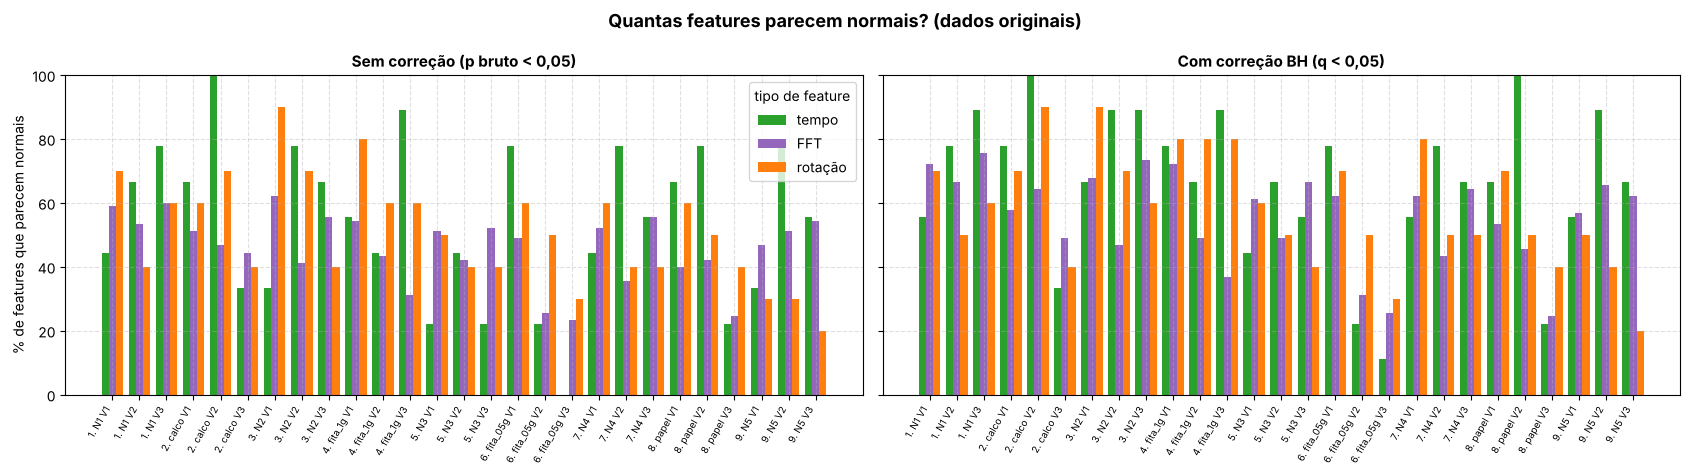

In [12]:
display(resumir_normalidade(resultado_original).round(1))
plotar_percentual_de_normais(resultado_original, "Quantas features parecem normais? (dados originais)")

### 5.1 — Mapa: onde está o desvio da normalidade

**O que buscamos:** ver **quais features** (não só quantas) se afastam da normal.

Cada quadrado é uma feature num grupo (condição e velocidade). A cor é a estatística **W do Shapiro-Wilk**, que vai de 0 a 1:

* **W perto de 1 (amarelo):** a distribuição é parecida com uma normal.
* **W menor (roxo):** o formato se afasta da normal. Quanto menor, mais torta ou "pontuda". Valores abaixo de 0,7 aparecem todos com a cor mais escura.

**O ponto preto** marca as features em que a normalidade foi **rejeitada mesmo após a correção BH** (q < 0,05). Quadrado amarelo com ponto preto é um caso de "o teste rejeita, mas o formato é quase normal", típico de amostra grande.

In [13]:
def montar_matriz_de_w(resultado, colunas):
    """Matrizes (feature x grupo) com W e com a marca de rejeição pelo critério BH."""
    resultado = resultado[resultado["feature"].isin(colunas)].copy()
    resultado["grupo"] = resultado["gravacao"] + " V" + resultado["velocidade"].astype(str)
    w = resultado.pivot(index="feature", columns="grupo", values="W").reindex(colunas)
    rejeitada = resultado.pivot(index="feature", columns="grupo", values="nao_normal_bh").reindex(colunas)
    ordem = (resultado[["grupo", "gravacao", "velocidade"]].drop_duplicates().sort_values(["velocidade", "gravacao"])["grupo"].tolist())
    return w[ordem], rejeitada[ordem]


def plotar_mapa_de_w(resultado, paineis, titulo):
    """Mapa de cores do W. 'paineis' é uma lista de (título, lista de features), um painel por item."""
    altura = 0.22 * max(len(colunas) for _, colunas in paineis) + 2
    fig, axs = plt.subplots(1, len(paineis), figsize=(8.5 * len(paineis), altura), squeeze=False)
    fig.subplots_adjust(wspace=0.45, left=0.08, right=0.9)
    for ax, (subtitulo, colunas) in zip(axs[0], paineis):
        w, rejeitada = montar_matriz_de_w(resultado, colunas)
        imagem = ax.imshow(w.to_numpy(dtype=float), cmap="viridis", vmin=0.7, vmax=1.0, aspect="auto")
        ax.set_xticks(range(w.shape[1]))
        ax.set_xticklabels(w.columns, rotation=60, ha="right", fontsize=7)
        ax.set_yticks(range(w.shape[0]))
        ax.set_yticklabels(w.index, fontsize=7)
        ax.grid(False)
        linhas, colunas_marcadas = np.where(rejeitada.to_numpy(dtype=float) == 1)
        ax.scatter(colunas_marcadas, linhas, s=8, color="black")
        ax.set_title(subtitulo, fontsize=11, fontweight="bold")
    fig.colorbar(imagem, ax=axs[0].tolist(), label="W de Shapiro-Wilk (1 = normal perfeita)", shrink=0.6)
    fig.suptitle(titulo, fontsize=13, fontweight="bold")
    plt.show()

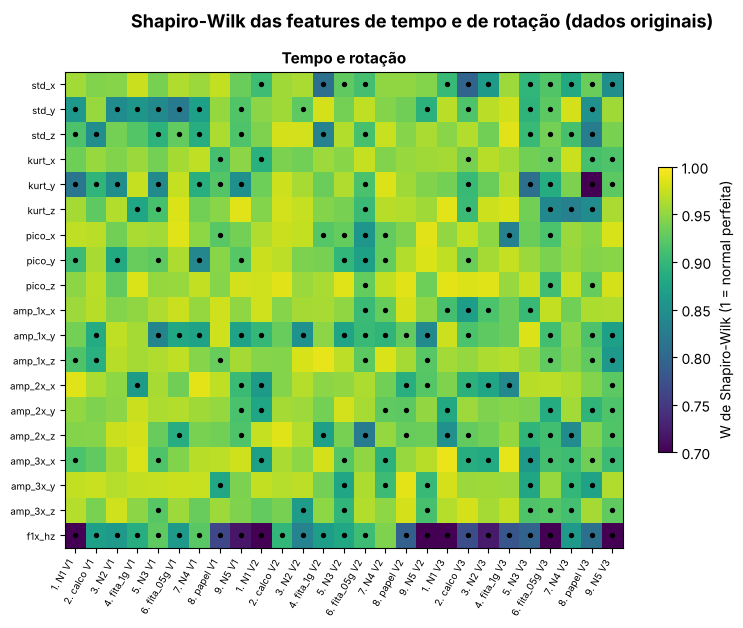

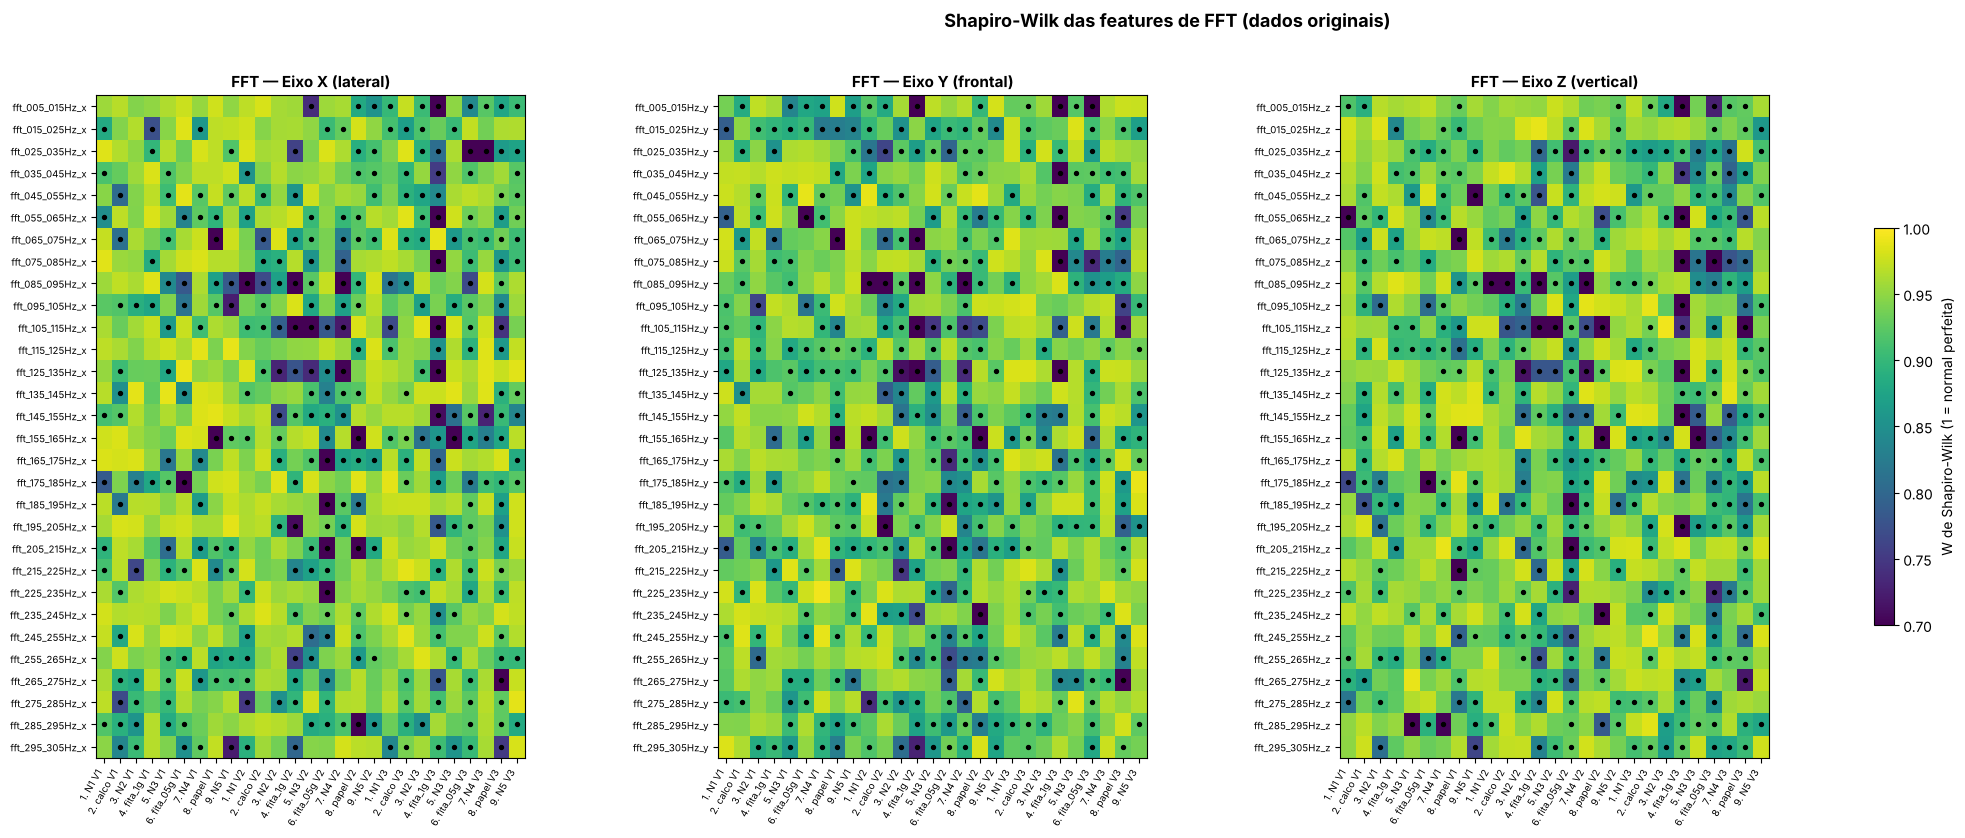

In [14]:
paineis_tempo_rotacao = [("Tempo e rotação", COLUNAS_TEMPO + COLUNAS_ROTACAO)]
paineis_fft = [(f"FFT — {NOMES_EIXOS[eixo]}", colunas_fft_do_eixo(eixo)) for eixo in EIXOS]

plotar_mapa_de_w(resultado_original, paineis_tempo_rotacao, "Shapiro-Wilk das features de tempo e de rotação (dados originais)")
plotar_mapa_de_w(resultado_original, paineis_fft, "Shapiro-Wilk das features de FFT (dados originais)")

### Conclusões do Passo 5

* **Cerca de 57% das features parecem normais** (q BH), somando as 27 gravações: 62% nas gravações normais e 50% nas anomalias. Por tipo: tempo 66%, rotação 59% e FFT 56%.
* **Não compare com os 11% da coleta anterior.** Lá cada grupo tinha cerca de 125 janelas; aqui tem cerca de 37, e com menos janelas o teste rejeita com mais dificuldade. A diferença vem principalmente do tamanho, não de os dados serem "mais normais".
* **Por gravação:** de 25% a 75%. As menos normais são **fita 0,5 g Vel 3 (25%)**, **papel Vel 3 (26%)** e **fita 0,5 g Vel 2 (32%)**, as mesmas gravações com rajadas e mudança de patamar no Notebook 01. Os lotes normais ficam entre 47% e 75%.
* **A correção BH muda mais aqui do que na coleta anterior** (por exemplo, N1 Vel 1: de 59% sem correção para 71% com). Com menos janelas os p-valores ficam perto de 0,05, e aí a correção faz diferença.
* **No mapa (5.1), a linha do `f1x_hz` fica escura em quase todas as gravações** (W mediano de 0,81; normalidade rejeitada em 96% das gravações). **Não é formato, é resolução:** com janelas de 5 s a rotação é medida em passos de 0,2 Hz, e cada gravação tem só de 2 a 7 valores diferentes. O Shapiro-Wilk rejeita qualquer feature com tantos empates.

### 5.2 — Os 5 normais juntos: o formato muda quando os lotes se misturam?

**O que buscamos:** o Notebook 06 vai treinar um detector **com todos os normais juntos**. Se cada lote for um sino, mas os sinos estiverem em lugares diferentes (o aquecimento muda a rotação de lote para lote), a mistura dos 5 vira uma distribuição **mais larga, achatada ou com vários montes**. Isso não é um defeito dos dados: é exatamente o "normal em diversas condições" que o detector precisa aprender. Mas muda a leitura dos limites de distância.

**O que o código faz:**

1. Junta as janelas dos 5 lotes de normal, em cada velocidade, num grupo só (`0. 5 normais juntos`), e roda os mesmos testes do Passo 5.
2. Compara com a **mediana dos 5 lotes testados separados**.
3. Mostra, para `FEATURE_EXEMPLO_LOTES` na `VELOCIDADE_EXEMPLO_LOTES`, o histograma dos 5 normais juntos, com cada lote numa cor.

**Cuidado:** os 5 normais juntos têm cerca de 185 janelas por velocidade, contra cerca de 37 de cada lote. Mais janelas tornam o teste mais exigente, então parte da queda nas "normais" vem só do tamanho. A **assimetria** e o **histograma** não dependem disso.

In [15]:
def testar_normais_juntos(features, colunas, condicao_normal=CONDICAO_NORMAL):
    """Roda o teste de normalidade nos lotes de normal juntos (um grupo por velocidade)."""
    normais = features[features["condicao"] == condicao_normal].copy()
    normais["gravacao"] = "0. 5 normais juntos"
    return testar_normalidade(normais, colunas)


def comparar_juntos_e_separados(resultado_juntos, resultado_original, condicao_normal=CONDICAO_NORMAL):
    """Por velocidade: o resumo dos normais juntos e a mediana do resumo dos lotes separados."""
    juntos = resumir_normalidade(resultado_juntos).droplevel("gravacao")
    separados = resumir_normalidade(resultado_original[resultado_original["condicao"] == condicao_normal])
    separados = separados.groupby("velocidade").median()
    colunas = ["% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]
    return pd.concat({"5 normais juntos": juntos[colunas], "lotes separados (mediana)": separados[colunas]}, axis=1).swaplevel(axis=1).sort_index(axis=1)


def plotar_mistura_dos_lotes(features, feature, velocidade, condicao_normal=CONDICAO_NORMAL):
    """Histograma dos normais juntos numa velocidade, com cada lote numa cor (barras empilhadas)."""
    normais = features[(features["condicao"] == condicao_normal) & (features["velocidade"] == velocidade)]
    lotes = sorted(normais["bloco"].unique())
    valores = [normais.loc[normais["bloco"] == lote, feature].to_numpy() for lote in lotes]
    todos = np.concatenate(valores)
    bordas = np.histogram_bin_edges(todos, bins=20)
    fig, ax = plt.subplots(figsize=(10, 4.2))
    ax.hist(valores, bins=bordas, stacked=True, label=lotes, color=plt.cm.Blues(np.linspace(0.35, 0.95, len(lotes))))
    eixo_x = np.linspace(todos.min(), todos.max(), 200)
    escala = len(todos) * (bordas[1] - bordas[0])
    ax.plot(eixo_x, norm.pdf(eixo_x, todos.mean(), todos.std(ddof=1)) * escala, color="black", linewidth=1.5, label="normal ajustada (juntos)")
    ax.set_xlabel(feature)
    ax.set_ylabel("número de janelas")
    ax.legend(title="lote", fontsize=9)
    ax.set_title(f"{feature}, Vel {velocidade}: os 5 lotes de normal juntos (cada cor é um lote)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

% normais (q BH)                            \
           5 normais juntos lotes separados (mediana)   
velocidade                                              
1                     11.01                     63.30   
2                      3.67                     52.29   
3                     10.09                     63.30   

           % tortas (|assim.| > limite)                            \
                       5 normais juntos lotes separados (mediana)   
velocidade                                                          
1                                 25.69                     15.60   
2                                 44.04                     18.35   
3                                 33.94                     15.60   

           mediana |assimetria|                            
               5 normais juntos lotes separados (mediana)  
velocidade                                                 
1                          0.58                      0.52  
2                          0.95                      0.57  
3                          0.68                      0.49

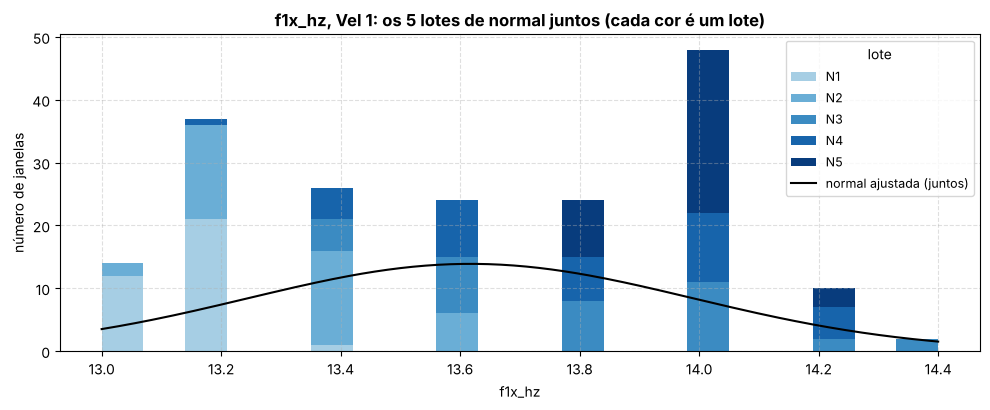

In [16]:
resultado_normais_juntos = testar_normais_juntos(features, COLUNAS_TODAS)
display(comparar_juntos_e_separados(resultado_normais_juntos, resultado_original).round(2))
plotar_mistura_dos_lotes(features, FEATURE_EXEMPLO_LOTES, VELOCIDADE_EXEMPLO_LOTES)

### Conclusões do Passo 5.2

| Vel | % normais: 5 juntos / lotes separados | % tortas: 5 juntos / lotes separados | mediana \|assimetria\|: 5 juntos / lotes separados |
| --- | --- | --- | --- |
| 1 | 11,0 / 63,3 | 25,7 / 15,6 | 0,58 / 0,52 |
| 2 | **3,7** / 52,3 | **44,0** / 18,4 | **0,95** / 0,57 |
| 3 | 10,1 / 63,3 | 33,9 / 15,6 | 0,68 / 0,49 |

* **Juntar os 5 lotes deixa as distribuições bem menos parecidas com o sino**, principalmente na Vel 2. Parte da queda nas "normais" vem do tamanho (cerca de 185 janelas contra 37), mas **a assimetria não depende do tamanho** e também sobe (até 0,95 na Vel 2).
* **O histograma do `f1x_hz` na Vel 1 mostra o porquê:** cada lote ocupa um trecho diferente (N1 entre 13,0 e 13,2 Hz, N5 entre 13,8 e 14,2 Hz), e a mistura fica larga e com vários montes, que a normal ajustada não acompanha.
* **Para o Notebook 06 (detector com todos os normais juntos):** o "normal" que ele vai aprender **não é um sino só**. Um limite baseado em média e desvio padrão (ou numa distância que supõe um único sino) pode ficar mal calibrado: largo demais no centro e apertado nas pontas. Isso favorece detectores que não supõem um formato (por exemplo, distância ao vizinho mais próximo) e reforça a avaliação deixando **um lote inteiro de fora**. É uma indicação para testar, não uma decisão.

## Passo 6 — Assimetria, histogramas e QQ-plots: o quanto e como se afastam

**O que buscamos:** o teste diz *se* a feature se afasta da normal. Agora queremos ver **o quanto** e **de que jeito**.

### 6.1 — W contra assimetria (cada ponto é uma feature num grupo)

* **Eixo horizontal:** a assimetria. A faixa amarela marca o intervalo "pouco torta" (|assimetria| ≤ 1).
* **Eixo vertical:** o W do Shapiro-Wilk. Quanto mais baixo, mais longe da normal.
* **Como interpretar:**
  * ponto **alto e dentro da faixa amarela:** normal ou quase;
  * ponto **baixo e fora da faixa:** claramente não normal e torto;
  * ponto **na faixa amarela, mas com W baixo:** não é por assimetria, e sim por outro defeito (por exemplo, caudas pesadas ou dois grupos misturados).

A tabela embaixo cruza o veredito do teste (BH) com a assimetria, nos quatro casos descritos no Passo 4.

### 6.2 — Histogramas e QQ-plots das features de exemplo

Para cada feature de exemplo (`FEATURES_EXEMPLO`), em `VELOCIDADE_EXEMPLO`:

* **Histograma azul (os 5 lotes de normal juntos) e vermelho (a anomalia):** as barras são os dados; a linha preta é a **normal que mais se parece com eles**. Quanto mais as barras seguem a linha, mais normal.
* **QQ-plot:** os dados padronizados contra uma normal ideal. **Pontos sobre a reta preta = normal.** Pontos que se curvam para cima nas pontas indicam cauda comprida para a direita. Pontos em "S" indicam caudas mais pesadas ou mais leves que a normal.

In [17]:
def selecionar_janelas(features, condicoes, velocidade):
    """Janelas de uma lista de condições numa velocidade."""
    return features[features["condicao"].isin(condicoes) & (features["velocidade"] == velocidade)]


def plotar_scatter_w_e_assimetria(resultado, titulo):
    """Cada ponto é uma feature num grupo: eixo x = assimetria, eixo y = W. Mostra o que o teste rejeita mas é quase simétrico."""
    validos = resultado[resultado["p_bruto"].notna()]
    fig, ax = plt.subplots(figsize=(9, 6))
    for tipo, cor in CORES_TIPO.items():
        parte = validos[validos["tipo"] == tipo]
        ax.scatter(parte["assimetria"], parte["W"], s=14, alpha=0.5, color=cor, label=tipo)
    ax.axvline(LIMITE_ASSIMETRIA, color="black", linestyle="--")
    ax.axvline(-LIMITE_ASSIMETRIA, color="black", linestyle="--")
    ax.axvspan(-LIMITE_ASSIMETRIA, LIMITE_ASSIMETRIA, color="gold", alpha=0.12)
    ax.set_xlabel("assimetria (0 = simétrica; positiva = cauda comprida para a direita)")
    ax.set_ylabel("W de Shapiro-Wilk (1 = normal perfeita)")
    ax.legend(title="tipo de feature")
    ax.set_title(titulo, fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()


def contar_casos_de_assimetria_e_teste(resultado):
    """Cruza o veredito do teste (BH) com a assimetria: as quatro combinações possíveis."""
    validos = resultado[resultado["p_bruto"].notna()]
    tabela = pd.crosstab(
        validos["nao_normal_bh"].map({True: "teste rejeita a normal", False: "teste não rejeita"}),
        validos["torta"].map({True: "|assimetria| > limite (torta)", False: "|assimetria| <= limite"}),
    )
    return tabela

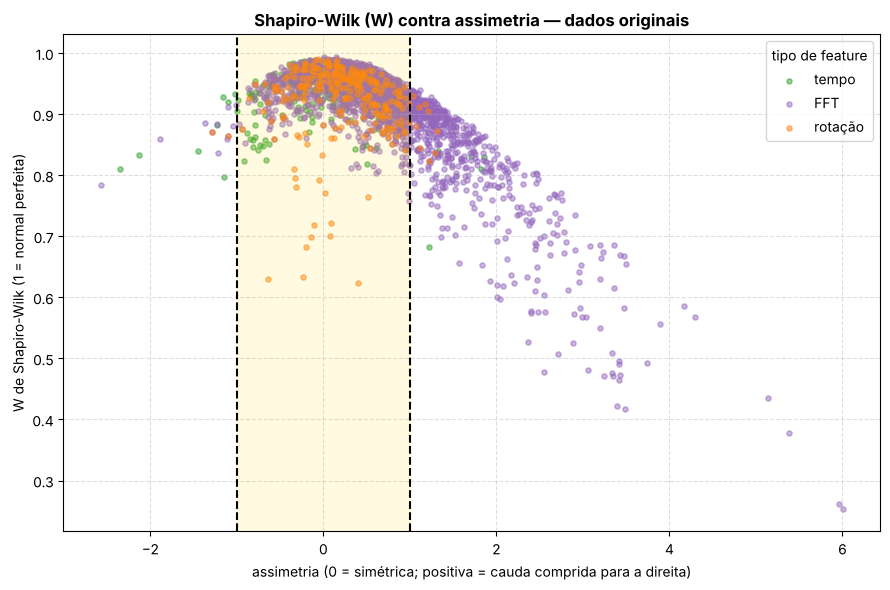

torta,|assimetria| <= limite,|assimetria| > limite (torta)
nao_normal_bh,,
teste não rejeita,1653,21
teste rejeita a normal,694,575


In [18]:
plotar_scatter_w_e_assimetria(resultado_original, "Shapiro-Wilk (W) contra assimetria — dados originais")
display(contar_casos_de_assimetria_e_teste(resultado_original))

In [19]:
def plotar_histogramas_e_qq(features, condicoes_ref, condicao, velocidade, colunas_exemplo):
    """Para cada feature: histograma da referência, histograma da anomalia (ambos com a normal ajustada) e QQ-plot das duas."""
    fig, axs = plt.subplots(len(colunas_exemplo), 3, figsize=(16, 3.3 * len(colunas_exemplo)), squeeze=False)
    for i, coluna in enumerate(colunas_exemplo):
        grupos = ((COR_REFERENCIA, condicoes_ref, "referência"), (COR_COMPARADA, [condicao], condicao))
        for j, (cor, condicoes, rotulo) in enumerate(grupos):
            valores = selecionar_janelas(features, condicoes, velocidade)[coluna].to_numpy()
            ax = axs[i, j]
            ax.hist(valores, bins=15, density=True, color=cor, alpha=0.6)
            eixo_x = np.linspace(valores.min(), valores.max(), 200)
            ax.plot(eixo_x, norm.pdf(eixo_x, valores.mean(), valores.std(ddof=1)), color="black", linewidth=1.5, label="normal ajustada")
            ax.set_title(f"{coluna} — {rotulo}", fontsize=10, fontweight="bold")
            ax.set_ylabel("densidade")
            if i == 0 and j == 0:
                ax.legend(fontsize=8)
            padronizados = np.sort((valores - valores.mean()) / valores.std(ddof=1))
            teoricos = norm.ppf((np.arange(1, len(valores) + 1) - 0.5) / len(valores))
            axs[i, 2].scatter(teoricos, padronizados, s=12, color=cor, alpha=0.7, label=rotulo)
        limite = [-3.5, 3.5]
        axs[i, 2].plot(limite, limite, color="black", linewidth=1)
        axs[i, 2].set_title(f"{coluna} — QQ-plot", fontsize=10, fontweight="bold")
        axs[i, 2].set_xlabel("quantil esperado se fosse normal")
        axs[i, 2].set_ylabel("quantil observado (padronizado)")
        axs[i, 2].legend(fontsize=8)
    fig.suptitle(f"Vel {velocidade} — formato das distribuições", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

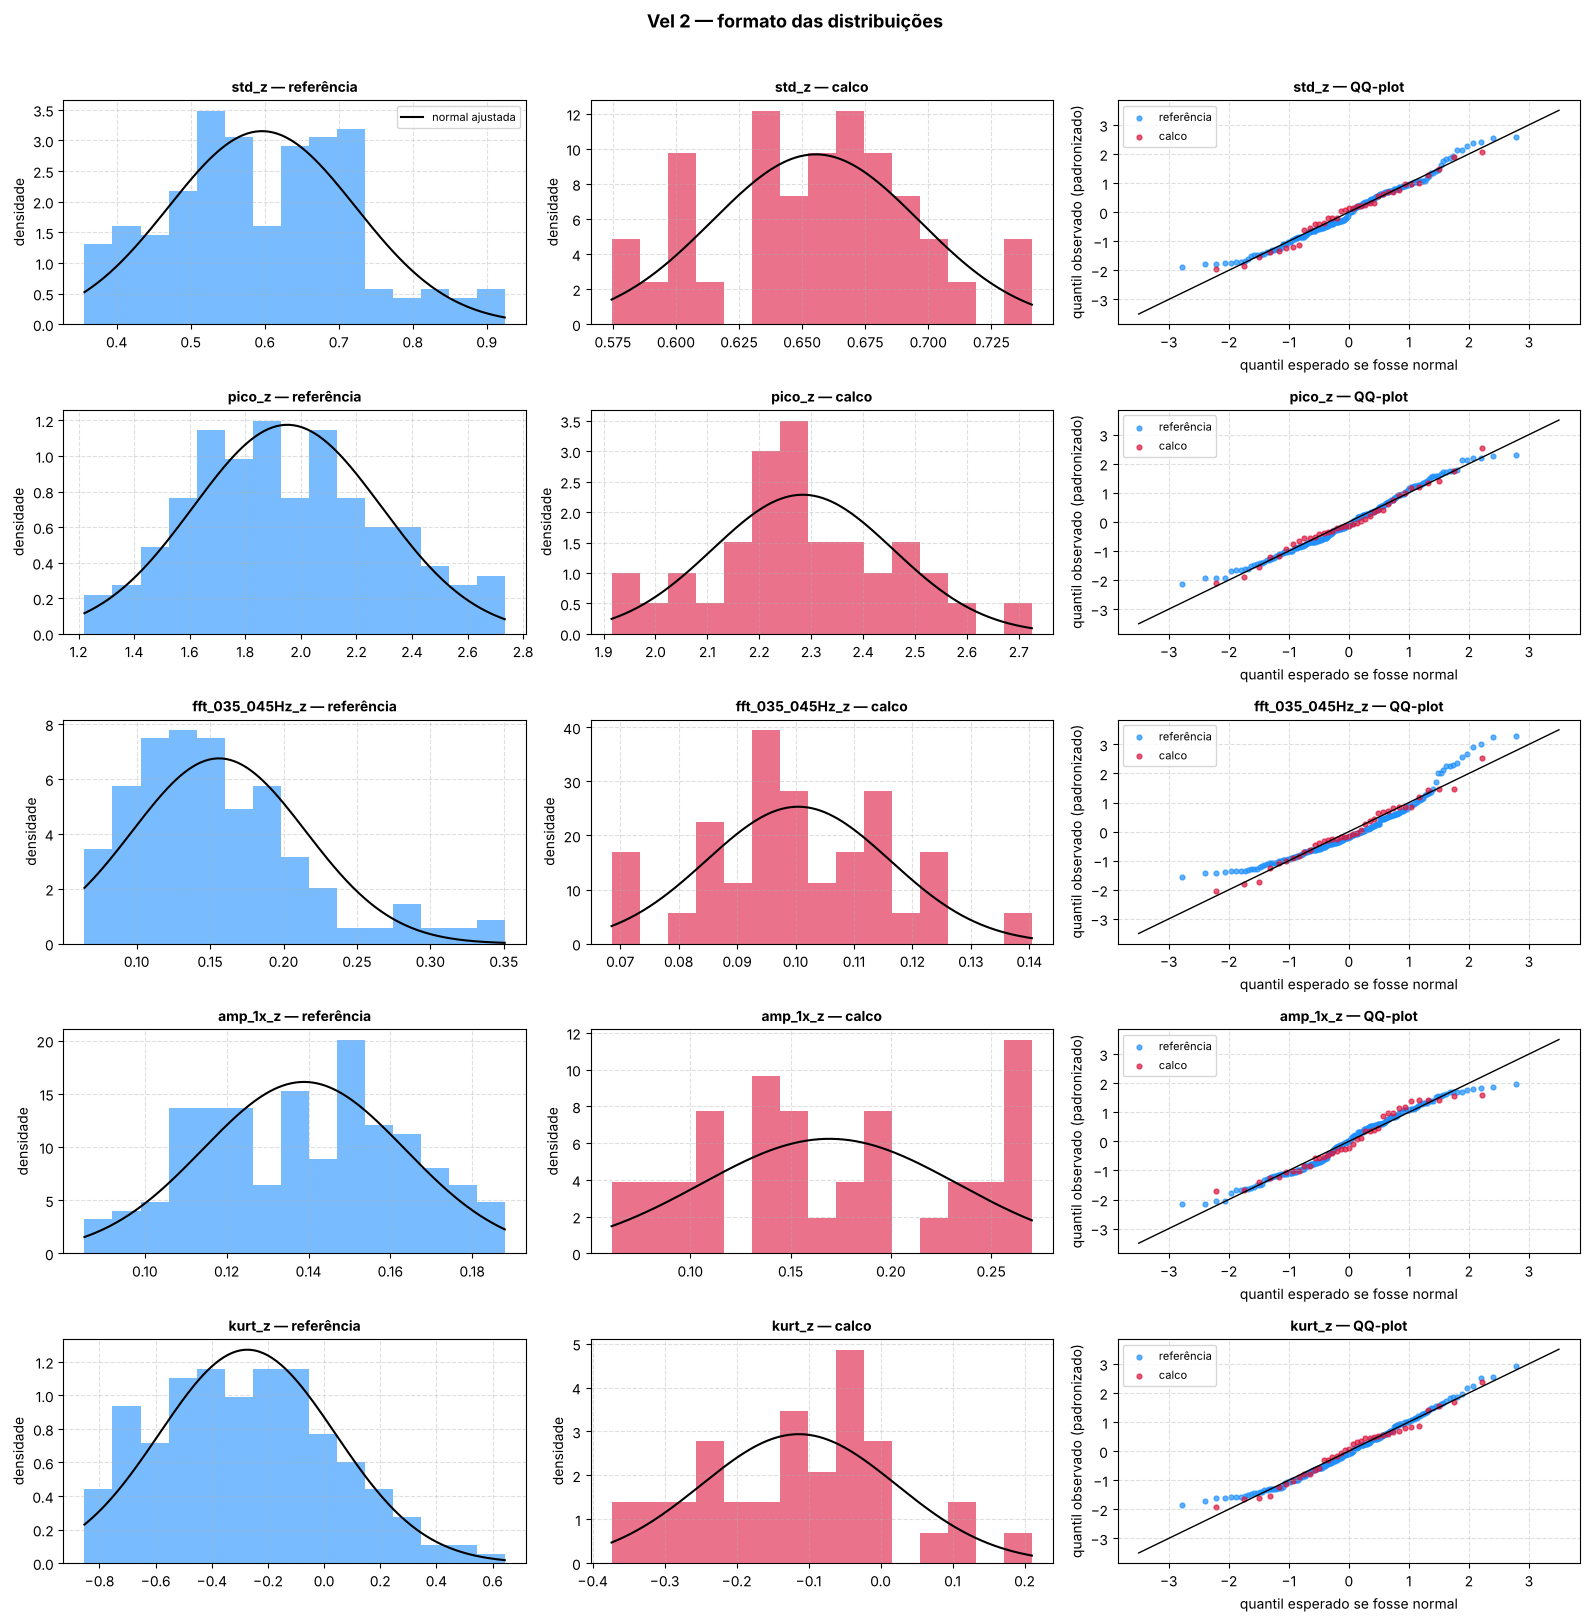

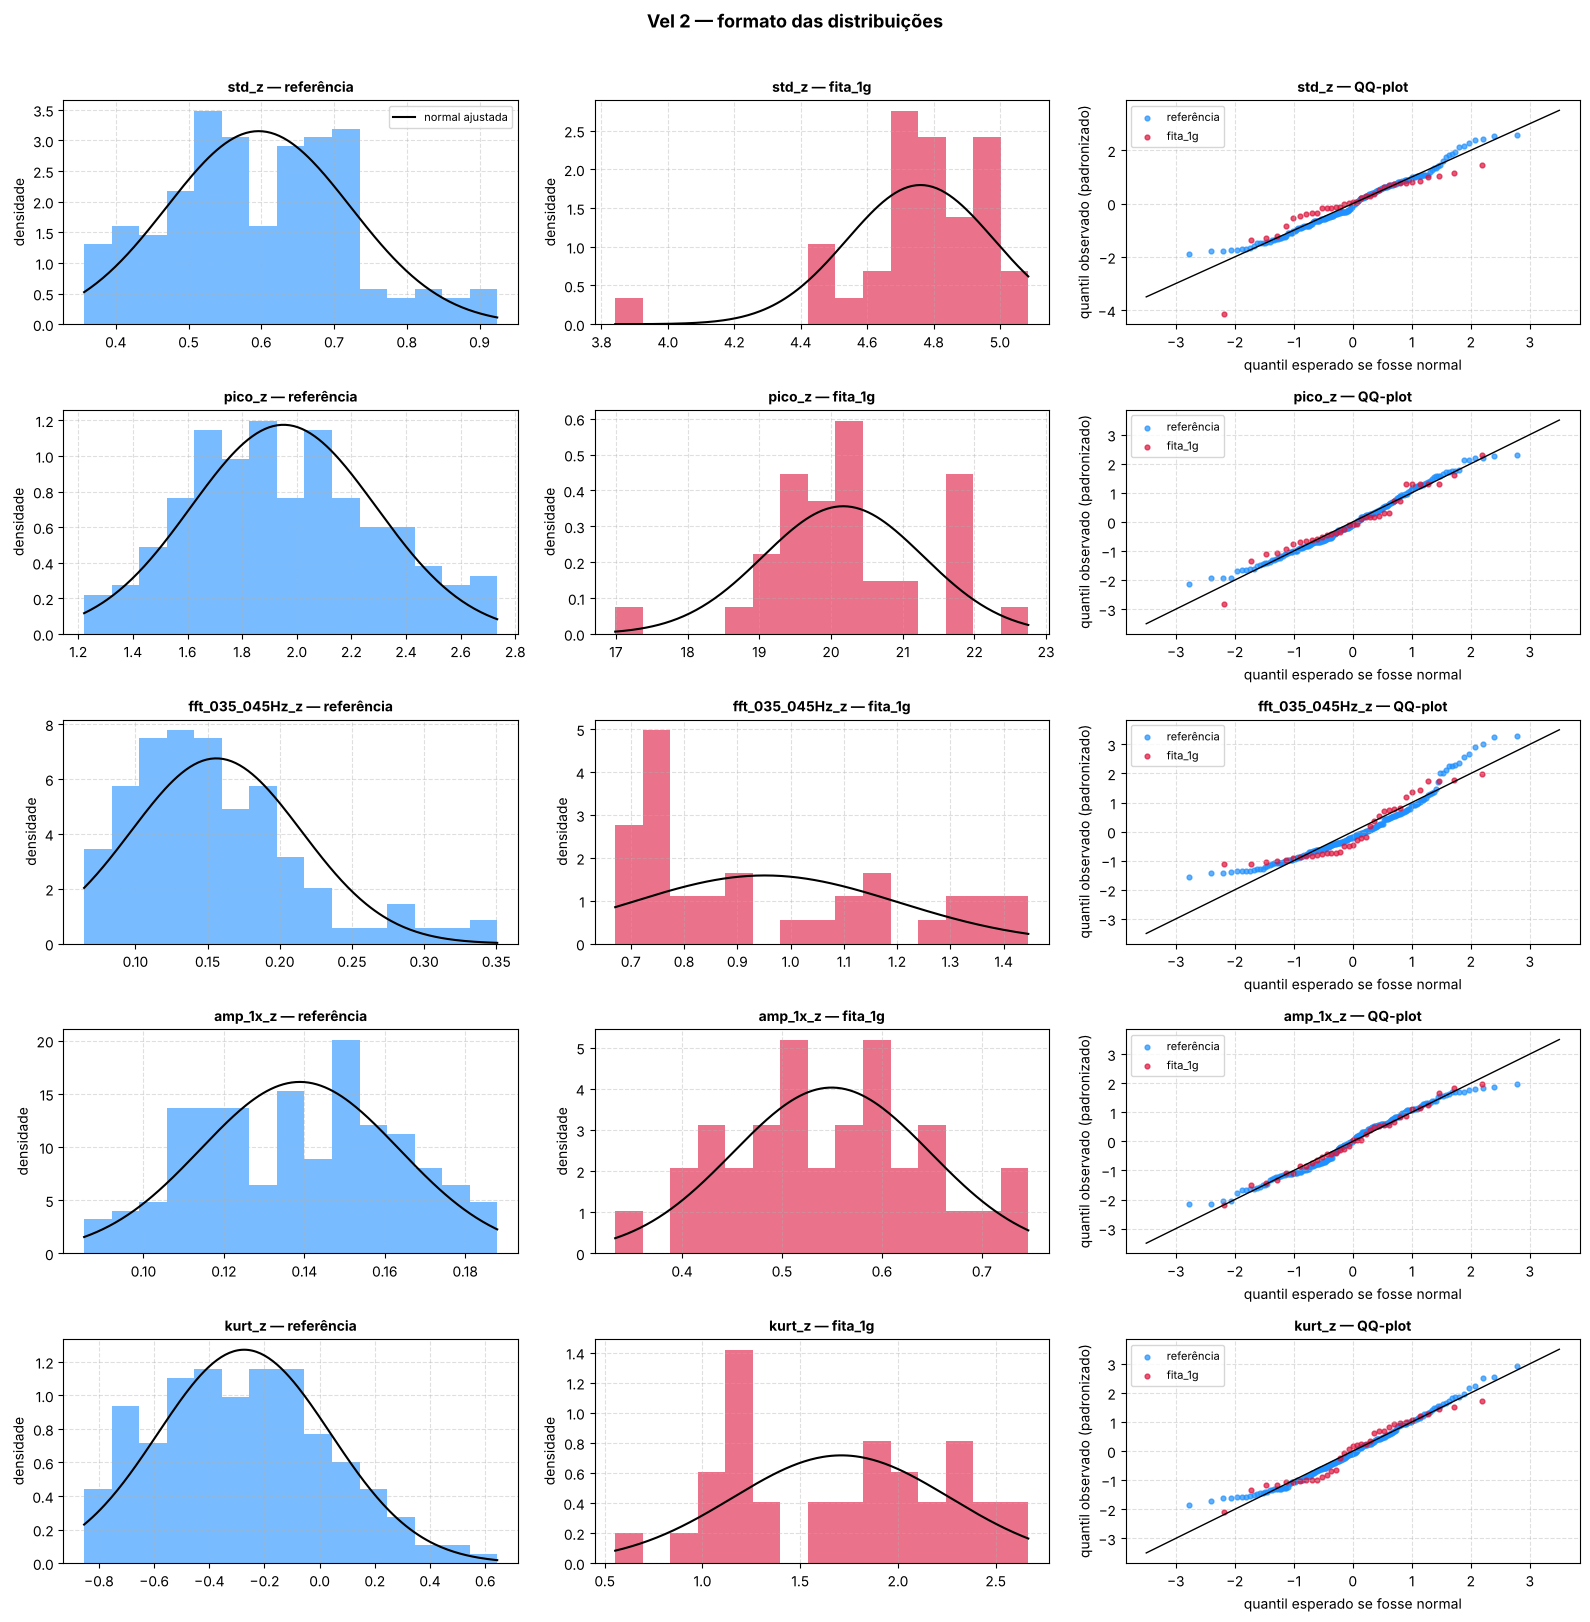

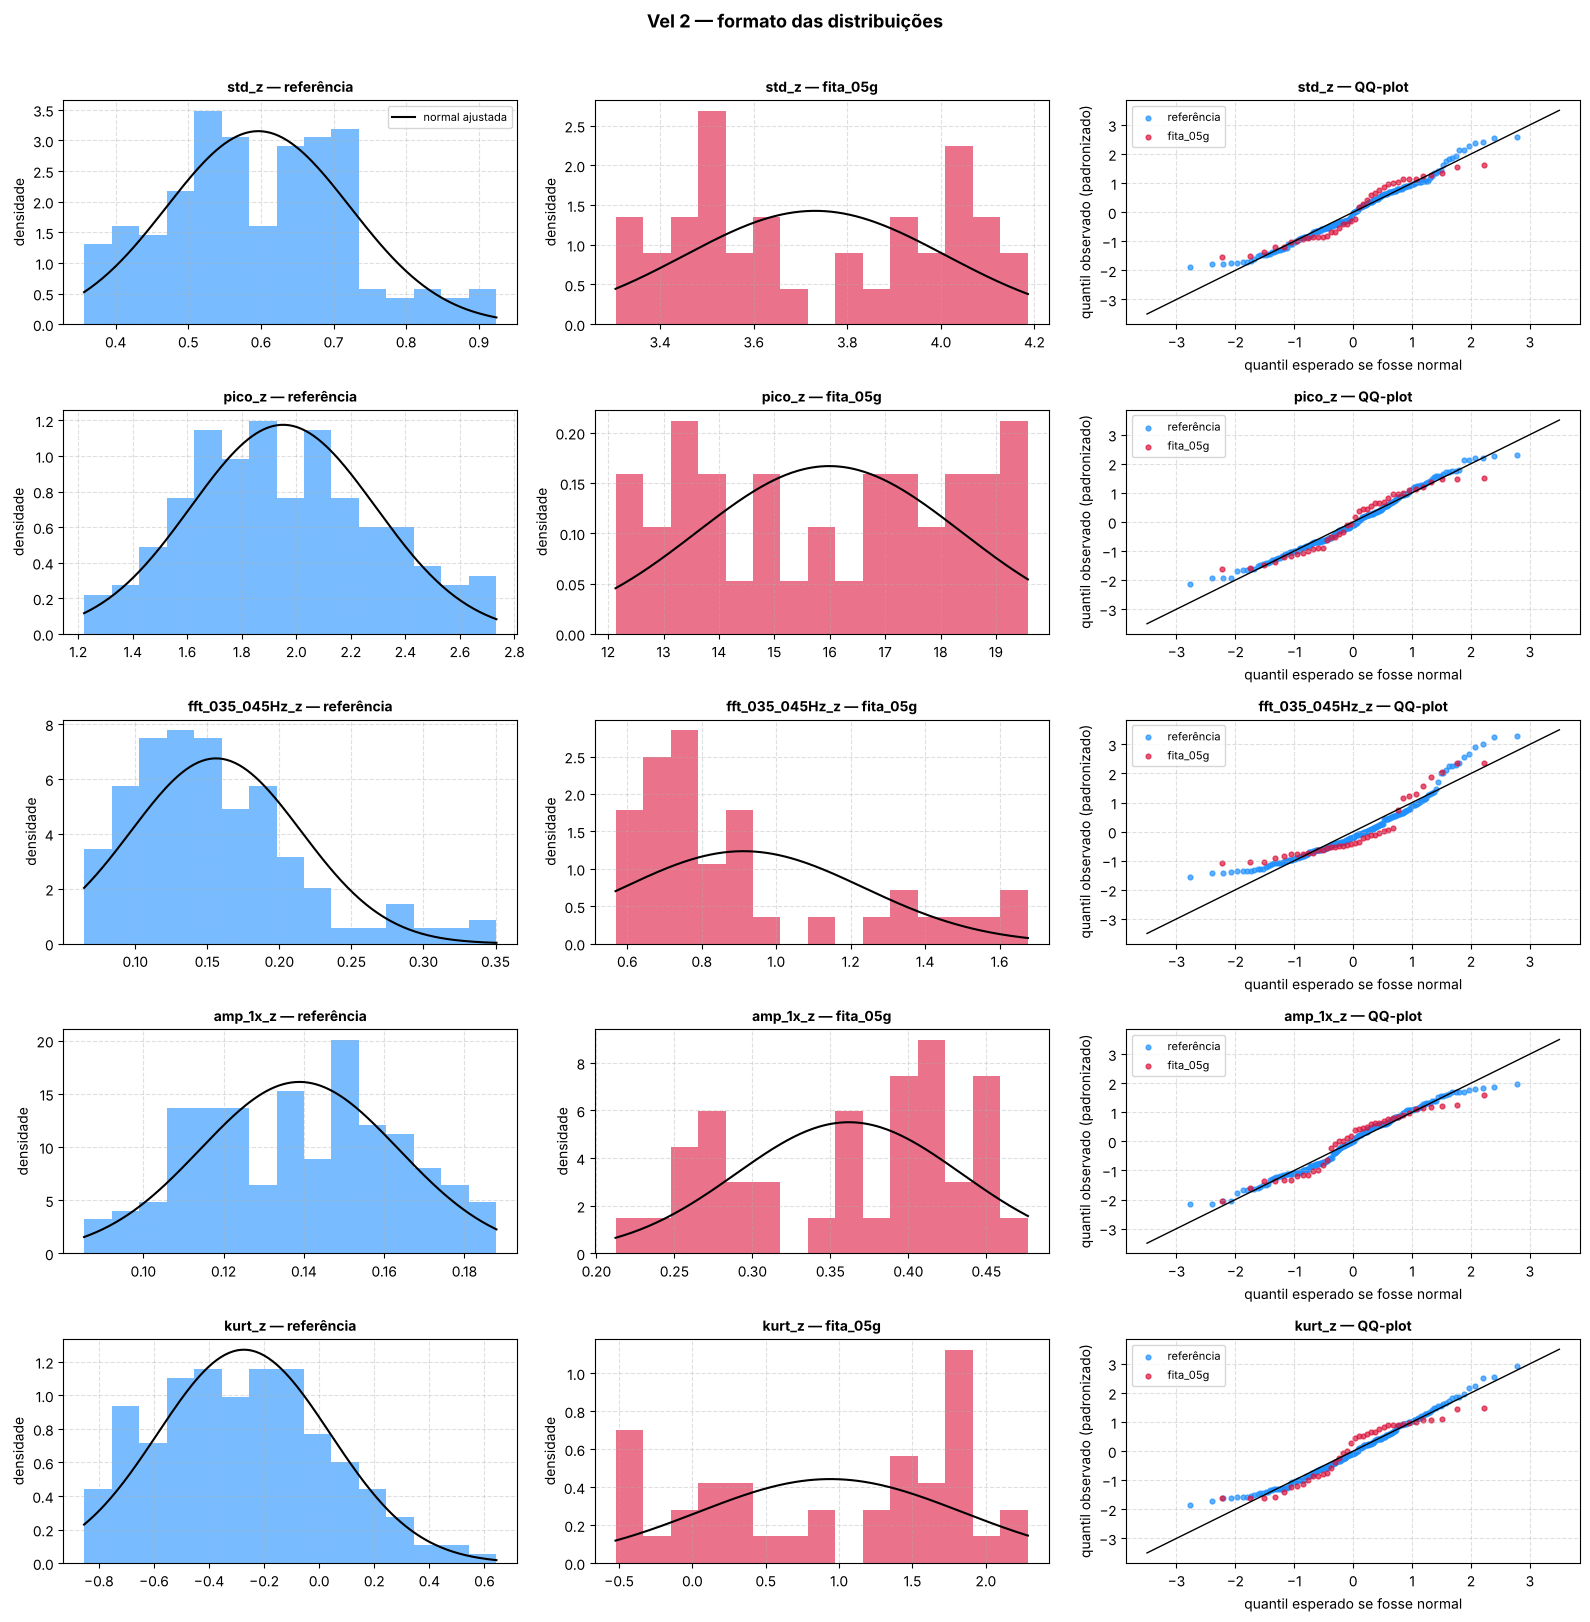

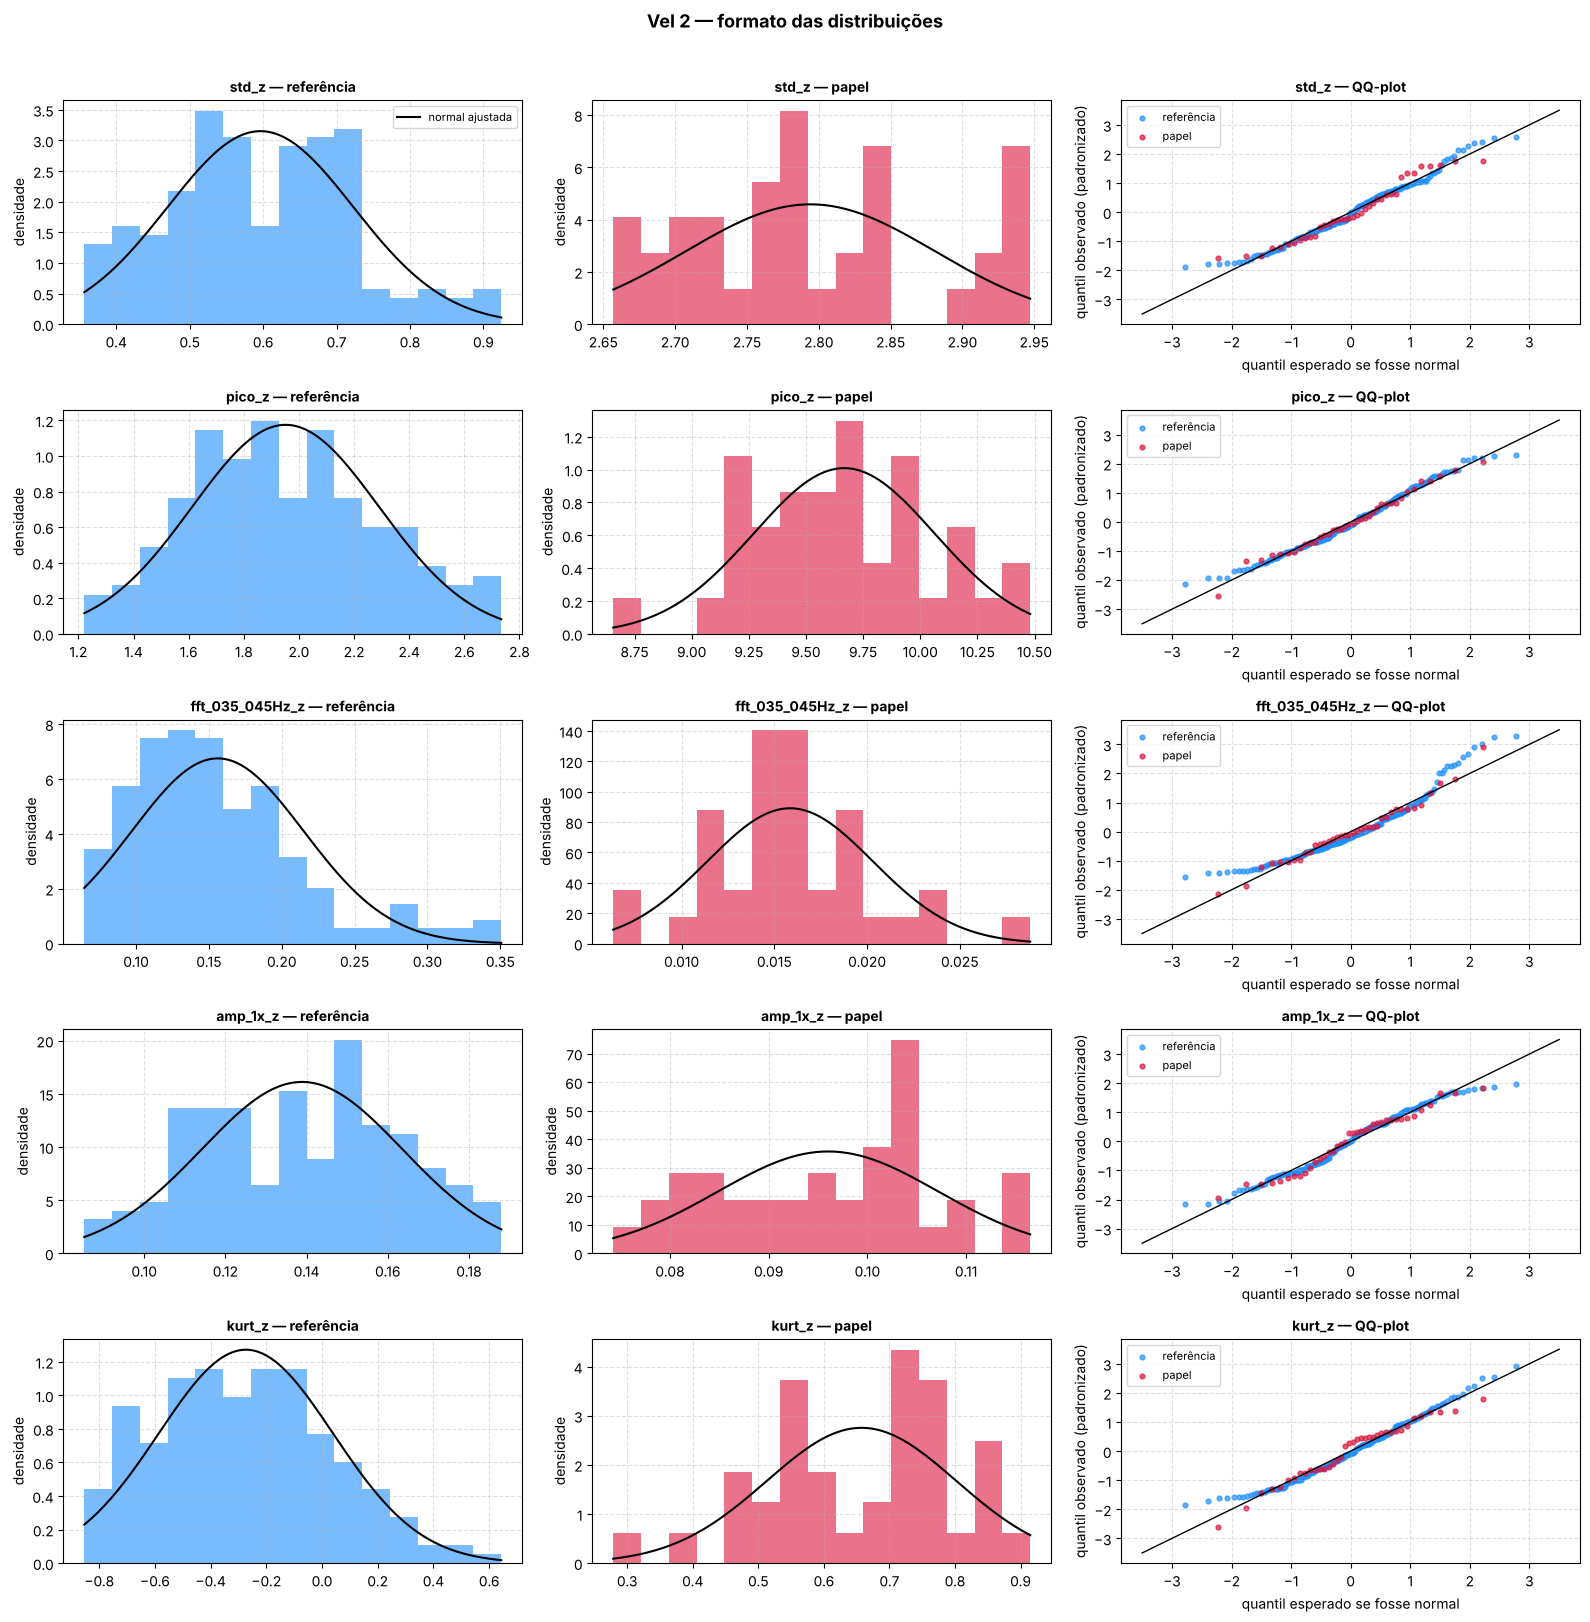

In [20]:
for condicao in condicoes_comparadas:
    plotar_histogramas_e_qq(features, CONDICOES_REFERENCIA, condicao, VELOCIDADE_EXEMPLO, FEATURES_EXEMPLO)

### 6.3 — Janelas atípicas: uma janela estranha pode estragar um grupo inteiro

**O que buscamos:** a assimetria e o Shapiro-Wilk são muito sensíveis a **uma única janela fora do normal**. Com cerca de 110 janelas, um só valor gigante já puxa a assimetria para perto do máximo possível (cerca de 10) e derruba o W. Vamos achar essas janelas.

**Como:** para cada feature, medimos o quanto cada janela se afasta da **mediana do grupo**, em unidades de "desvio robusto" (o MAD, que, ao contrário do desvio padrão, **não é puxado pelo próprio valor extremo**). Valores acima de `LIMITE_Z_ROBUSTO` são extremos. Uma janela é **atípica** quando tem pelo menos `MIN_FEATURES_ATIPICAS` features extremas ao mesmo tempo.

**Por que olhar a janela e não a feature:** uma janela com muitas features extremas de uma vez indica um **evento no sinal** (por exemplo, mexer no ventilador, uma batida, ligar ou desligar), e não uma flutuação normal de uma feature.

**Como ler a tabela:**

* `janela` e `inicio_s`: onde a janela está dentro da base (a janela 0 é o início da gravação).
* `features_extremas`: em quantas das 109 features ela é extrema.
* Janelas **no começo ou no fim** da gravação são suspeitas de manuseio. Confira no sinal bruto antes de decidir cortar.

A segunda parte refaz o teste de normalidade **sem essas janelas**, só nos grupos afetados, para mostrar o tamanho do estrago.

In [21]:
def encontrar_janelas_atipicas(features, colunas, limite_z=LIMITE_Z_ROBUSTO, min_features=MIN_FEATURES_ATIPICAS):
    """Janelas com muitas features extremas ao mesmo tempo, dentro da própria gravação.

    Uma feature é extrema numa janela quando ela fica a mais de limite_z desvios robustos da mediana do grupo.
    O desvio robusto é 1,4826 x MAD (mediana dos desvios absolutos), que não é puxado pelos valores extremos.
    """
    linhas = []
    for (gravacao, velocidade), grupo in features.groupby(["gravacao", "velocidade"]):
        valores = grupo[colunas]
        mediana = valores.median()
        desvio_robusto = 1.4826 * (valores - mediana).abs().median()
        z_robusto = (valores - mediana) / desvio_robusto.replace(0, np.nan)
        n_extremas = (z_robusto.abs() > limite_z).sum(axis=1)
        for indice in n_extremas[n_extremas >= min_features].index:
            linhas.append({
                "gravacao": gravacao, "velocidade": velocidade, "janela": int(grupo.loc[indice, "janela"]),
                "inicio_s": int(grupo.loc[indice, "janela"]) * JANELA_S, "features_extremas": int(n_extremas[indice]),
                "indice": indice,
            })
    colunas_tabela = ["gravacao", "velocidade", "janela", "inicio_s", "features_extremas", "indice"]
    return pd.DataFrame(linhas, columns=colunas_tabela).sort_values(["gravacao", "velocidade", "janela"])

In [22]:
janelas_atipicas = encontrar_janelas_atipicas(features, COLUNAS_TODAS)
janelas_por_base = features.groupby(["gravacao", "velocidade"]).size()

if janelas_atipicas.empty:
    print("Nenhuma janela atípica encontrada com estes limites.")
else:
    display(janelas_atipicas.drop(columns="indice").set_index(["gravacao", "velocidade"]))
    for gravacao, velocidade in janelas_atipicas[["gravacao", "velocidade"]].drop_duplicates().itertuples(index=False):
        total = int(janelas_por_base[(gravacao, velocidade)])
        print(f"{gravacao} Vel {velocidade}: a base tem {total} janelas (de 0 a {total - 1}).")

janela  inicio_s  features_extremas
gravacao    velocidade                                     
4. fita_1g  3               18        90                 16
            3               20       100                 15
            3               33       165                 10
6. fita_05g 2                0         0                 10

4. fita_1g Vel 3: a base tem 35 janelas (de 0 a 34).
6. fita_05g Vel 2: a base tem 38 janelas (de 0 a 37).


In [23]:
def testar_sem_janelas_atipicas(features, janelas_atipicas, colunas):
    """Refaz o teste de normalidade sem as janelas atípicas, só nos grupos que tinham alguma."""
    grupos_afetados = janelas_atipicas[["gravacao", "velocidade"]].drop_duplicates()
    limpa = features.drop(index=janelas_atipicas["indice"])
    limpa = limpa.merge(grupos_afetados, on=["gravacao", "velocidade"])
    antes = features.merge(grupos_afetados, on=["gravacao", "velocidade"])
    return testar_normalidade(antes, colunas), testar_normalidade(limpa, colunas)


def comparar_com_e_sem_atipicas(resultado_com, resultado_sem):
    """Resumo lado a lado, por grupo afetado, com e sem as janelas atípicas."""
    colunas_resumo = ["features testadas", "% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]
    com = resumir_normalidade(resultado_com)[colunas_resumo]
    sem = resumir_normalidade(resultado_sem)[colunas_resumo]
    return pd.concat({"com as atípicas": com, "sem as atípicas": sem}, axis=1).swaplevel(axis=1).sort_index(axis=1)

In [24]:
if not janelas_atipicas.empty:
    resultado_com, resultado_sem = testar_sem_janelas_atipicas(features, janelas_atipicas, COLUNAS_TODAS)
    display(comparar_com_e_sem_atipicas(resultado_com, resultado_sem).round(1))

% normais (q BH)                  \
                        com as atípicas sem as atípicas   
gravacao    velocidade                                    
4. fita_1g  3                      45.0            50.5   
6. fita_05g 2                      32.1            27.5   

                       % tortas (|assim.| > limite)                  \
                                    com as atípicas sem as atípicas   
gravacao    velocidade                                                
4. fita_1g  3                                  41.3            38.5   
6. fita_05g 2                                  33.0            33.9   

                       features testadas                 mediana |assimetria|  \
                         com as atípicas sem as atípicas      com as atípicas   
gravacao    velocidade                                                          
4. fita_1g  3                      109.0           109.0                  0.9   
6. fita_05g 2                      109.0           109.0                  0.8   

                                        
                       sem as atípicas  
gravacao    velocidade                  
4. fita_1g  3                      0.8  
6. fita_05g 2                      0.8

### Conclusões do Passo 6

**O quanto se afastam (6.1), nos 2.943 testes:**
* **1.653** não rejeitam a normalidade e não são tortos;
* **694** rejeitam, mas a feature **não é torta** (|assimetria| ≤ 1);
* **575 (20%)** rejeitam **e** são tortos;
* só **21** são tortos sem o teste rejeitar (poucas janelas para o teste notar).

A maior parte das rejeições é de formato **um pouco fora do sino**, como na coleta anterior.

**Como se afastam (6.2, Vel 2):**
* **Os 5 normais juntos** ficam perto da reta do QQ-plot em `std_z`, `pico_z`, `amp_1x_z` e `kurt_z`. A exceção é a faixa de **35–45 Hz**, com cauda para a direita (algumas janelas com o pico bem mais alto), tanto no normal quanto nas anomalias.
* **Nas anomalias** os histogramas são mais "espalhados", às vezes com **dois montes**: na fita 0,5 g, `std_z` (entre 3,3 e 4,2 m/s²), `amp_1x_z` e `kurt_z`. Com 38 janelas, parte disso é ruído do histograma, mas o desenho combina com uma vibração que muda com o ciclo da oscilação.

**Janelas atípicas (6.3):**
* **Só 4 janelas**, contra mais de 30 na coleta anterior: janelas 18, 20 e 33 da **fita 1 g Vel 3** (90, 100 e 165 s) e a janela 0 da **fita 0,5 g Vel 2**.
* **Tirá-las quase não muda nada** (fita 1 g Vel 3: de 45,0% para 50,5% de normais; fita 0,5 g Vel 2: de 32,1% para 27,5%).
* **Não há trecho longo de transição** dentro das gravações, como o da fita Vel 2 da coleta anterior, coerente com o motor já aquecido entre os blocos (Notebook 01).

**Decisão:** **manter todas as janelas**, como na coleta anterior.

## Passo 7 — Autocorrelação: as janelas são independentes?

**O que buscamos:** medir o quanto as ressalvas da Escolha 2 pesam nos nossos dados.

**A pergunta:** se uma janela tem um valor alto numa feature, a **janela seguinte** também tende a ter? Isso se mede pela **autocorrelação de lag 1**: a correlação de cada feature com ela mesma deslocada em uma janela, dentro de cada base.

* **Perto de 0:** janelas vizinhas são independentes. Os p-valores são confiáveis.
* **Perto de 1:** janelas vizinhas são cópias uma da outra (por exemplo, deriva lenta). Os p-valores ficam **otimistas demais**.
* **Janelas equivalentes:** uma estimativa de quantas janelas "realmente independentes" a base vale, calculada como n × (1 − r) / (1 + r), em que r é a autocorrelação mediana (valores negativos contam como 0).

**Cuidado ao ler:** com cerca de 37 janelas por gravação, a autocorrelação de **uma** feature tem ruído grande, de cerca de ±0,16 (o Passo 7.3 mede isso por simulação). A mediana das 109 features é bem mais estável, mas as features não são independentes entre si. Só consideramos autocorrelação relevante se a mediana ficar **claramente acima de 0,2**.

In [25]:
def calcular_autocorrelacao_lag1(features, colunas):
    """Correlação de cada feature com ela mesma na janela seguinte, dentro de cada base. Devolve (base x feature)."""
    linhas = {}
    for base, grupo in features.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        linhas[base] = {c: grupo[c].autocorr(lag=1) for c in colunas}
    return pd.DataFrame(linhas).T


def resumir_autocorrelacao(autocorrelacao, features):
    """Por base: mediana e percentil 90 da autocorrelação, e quantas janelas 'independentes' isso equivale."""
    n_janelas = features.groupby("base", sort=False).size()
    mediana = autocorrelacao.median(axis=1)
    resumo = pd.DataFrame({
        "janelas": n_janelas,
        "autocorrelacao mediana": mediana,
        "autocorrelacao p90": autocorrelacao.quantile(0.9, axis=1),
    })
    resumo["janelas equivalentes"] = n_janelas * (1 - mediana.clip(lower=0)) / (1 + mediana.clip(lower=0))
    return resumo

In [26]:
autocorrelacao = calcular_autocorrelacao_lag1(features, COLUNAS_TODAS)
display(resumir_autocorrelacao(autocorrelacao, features).round(2))

,janelas,autocorrelacao mediana,autocorrelacao p90,janelas equivalentes
ventilador_normal_vel_1_lote_1,34,-0.22,0.07,34.00
ventilador_normal_vel_2_lote_1,35,-0.34,0.12,35.00
ventilador_normal_vel_3_lote_1,36,-0.29,0.16,36.00
calco_vel_1,35,-0.14,0.15,35.00
calco_vel_2,37,-0.09,0.29,37.00
calco_vel_3,43,-0.44,0.04,43.00
ventilador_normal_vel_1_lote_2,38,-0.19,0.02,38.00
ventilador_normal_vel_2_lote_2,36,-0.14,0.31,36.00
ventilador_normal_vel_3_lote_2,35,-0.34,0.04,35.00
fita_1g_vel_1,33,-0.19,0.00,33.00


### 7.2 — Ciclo lento: o que está por trás da autocorrelação

**O que buscamos:** se a autocorrelação não for perto de 0 (positiva **ou negativa**), algo repete de janela em janela. Vamos procurar **um ciclo lento** na intensidade da vibração.

**Como:** para cada base, medimos o desvio padrão do sinal a cada `BLOCO_MODULACAO_S` (0,25 s), o que dá uma curva de "quanto o ventilador vibra" ao longo do tempo. Depois olhamos **qual período se repete mais** nessa curva.

**Como ler:**

* **Gráfico da esquerda:** se a curva sobe e desce com regularidade, existe um ciclo.
* **Gráfico da direita:** o pico mostra o **período do ciclo** em segundos. As linhas marcam o tamanho da janela (5 s) e de duas janelas (10 s).
* **Tabela:** o período dominante, o quanto a intensidade oscila em torno da média e a razão entre os valores altos e baixos do ciclo.

**Por que isso importa para nossas janelas de 5 s:** se o ciclo dura cerca de 10 s, **cada janela pega só uma metade do ciclo**. Uma janela cai na fase "forte", a seguinte na fase "fraca", e assim por diante. Isso gera autocorrelação **negativa**, distribuições **achatadas ou com dois montes** (não parecidas com o sino) e mais variação **dentro** de uma mesma condição.

In [27]:
def medir_ciclo_lento(df, eixo=EIXO_MODULACAO, bloco_s=BLOCO_MODULACAO_S):
    """Intensidade (desvio padrão) a cada bloco curto e o espectro dessa série.

    Devolve (tempo_s, intensidade, periodos_s, forca_do_ciclo), com os períodos de FAIXA_PERIODO_MODULACAO_S.
    """
    tamanho = int(bloco_s * TAXA_AMOSTRAGEM_HZ)
    n_blocos = len(df) // tamanho
    blocos = df[eixo].to_numpy()[: n_blocos * tamanho].reshape(n_blocos, tamanho)
    intensidade = blocos.std(axis=1, ddof=1)
    espectro = np.abs(np.fft.rfft((intensidade - intensidade.mean()) * np.hanning(n_blocos)))
    frequencias_ciclo = np.fft.rfftfreq(n_blocos, d=bloco_s)
    na_faixa = (frequencias_ciclo >= 1 / FAIXA_PERIODO_MODULACAO_S[1]) & (frequencias_ciclo <= 1 / FAIXA_PERIODO_MODULACAO_S[0])
    periodos = 1 / frequencias_ciclo[na_faixa]
    return np.arange(n_blocos) * bloco_s, intensidade, periodos, espectro[na_faixa]


def resumir_ciclo_lento(bases):
    """Por base: o período do ciclo dominante e o quanto a intensidade oscila ao longo dele."""
    linhas = {}
    for nome, df in bases.items():
        _, intensidade, periodos, forca = medir_ciclo_lento(df)
        linhas[nome] = {
            "periodo dominante (s)": periodos[forca.argmax()],
            "oscilação (desvio / média, %)": 100 * intensidade.std() / intensidade.mean(),
            "pico / vale (percentil 95 / 5)": np.percentile(intensidade, 95) / np.percentile(intensidade, 5),
        }
    return pd.DataFrame(linhas).T


def plotar_ciclo_lento(bases, duracao_s=120):
    """Por base: intensidade ao longo do tempo (esquerda) e força de cada período (direita)."""
    fig, axs = plt.subplots(len(bases), 2, figsize=(14, 2.6 * len(bases)), squeeze=False)
    for i, (nome, df) in enumerate(bases.items()):
        tempo, intensidade, periodos, forca = medir_ciclo_lento(df)
        axs[i, 0].plot(tempo, intensidade, linewidth=0.8, color="slategray")
        axs[i, 0].set_xlim(0, duracao_s)
        axs[i, 0].set_title(f"{nome} — desvio padrão de {EIXO_MODULACAO} a cada {BLOCO_MODULACAO_S} s", fontsize=10, fontweight="bold")
        axs[i, 0].set_ylabel(UNIDADE)
        axs[i, 1].plot(periodos, forca, color="slategray")
        axs[i, 1].axvline(JANELA_S, color="crimson", linestyle="--", label=f"janela de {JANELA_S} s")
        axs[i, 1].axvline(2 * JANELA_S, color="black", linestyle=":", label=f"2 janelas ({2 * JANELA_S} s)")
        axs[i, 1].set_title("Força de cada período do ciclo", fontsize=10, fontweight="bold")
        if i == 0:
            axs[i, 1].legend(fontsize=8)
    axs[-1, 0].set_xlabel("Tempo (s)")
    axs[-1, 1].set_xlabel("Período do ciclo (s)")
    plt.tight_layout()
    plt.show()

,periodo dominante (s),"oscilação (desvio / média, %)",pico / vale (percentil 95 / 5)
ventilador_normal_vel_1_lote_1,17.15,9.24,1.34
ventilador_normal_vel_2_lote_1,11.73,17.15,1.72
ventilador_normal_vel_3_lote_1,9.53,13.77,1.58
calco_vel_1,17.90,13.23,1.52
calco_vel_2,3.94,18.41,1.84
calco_vel_3,9.50,21.21,1.94
ventilador_normal_vel_1_lote_2,8.41,8.96,1.35
ventilador_normal_vel_2_lote_2,11.31,14.48,1.63
ventilador_normal_vel_3_lote_2,8.90,11.06,1.41
fita_1g_vel_1,16.90,12.97,1.53


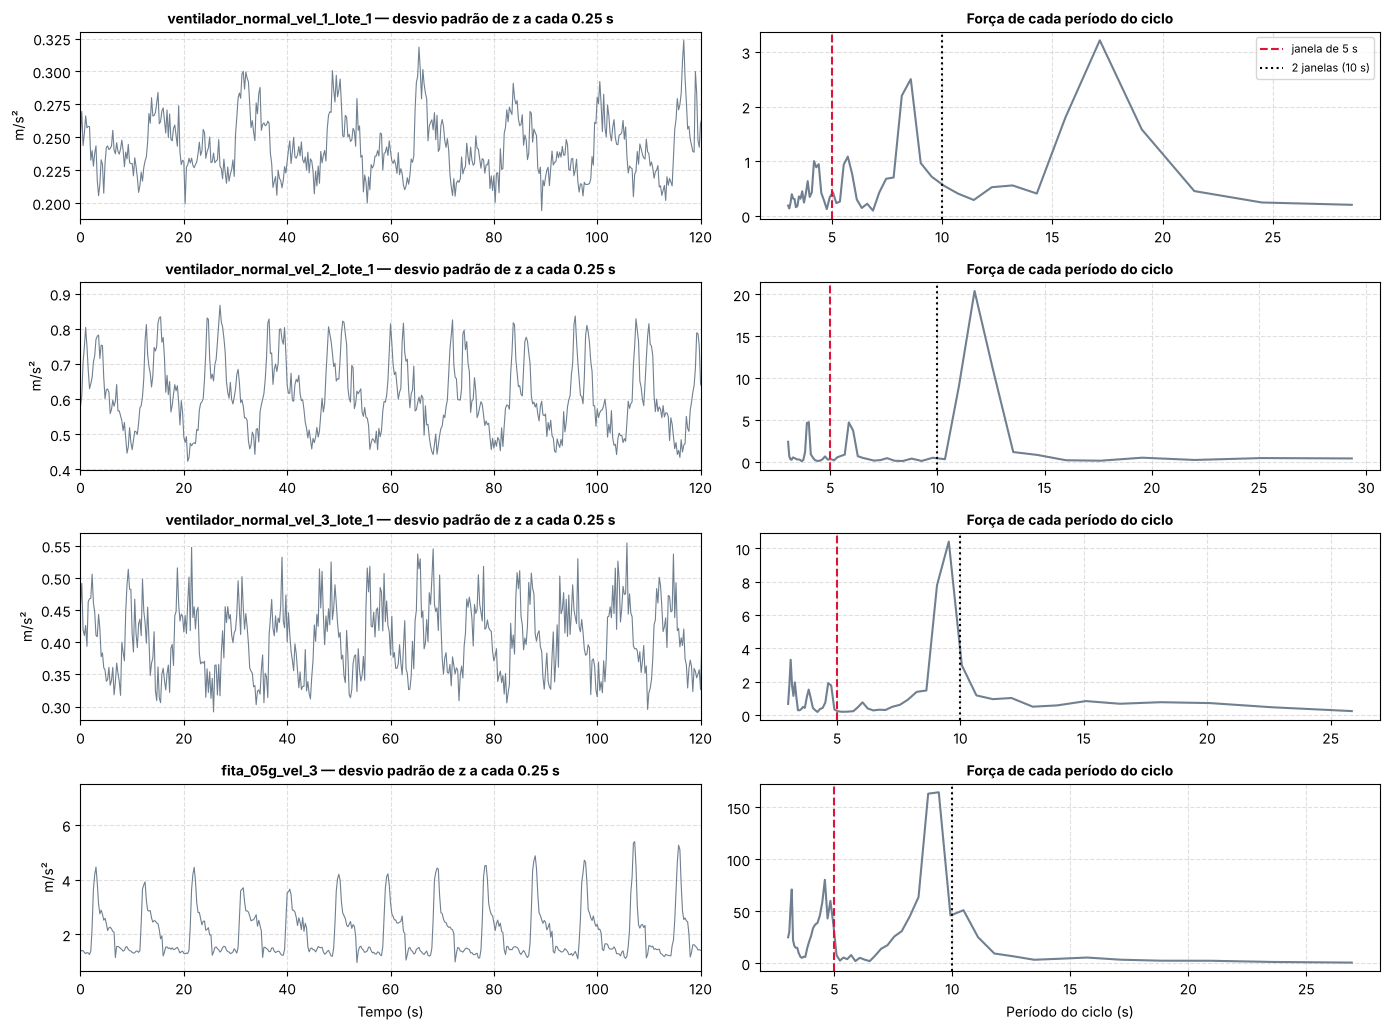

In [28]:
display(resumir_ciclo_lento(bases).round(2))
plotar_ciclo_lento({nome: bases[nome] for nome in BASES_EXEMPLO_CICLO if nome in bases})

### 7.2.1 — O ciclo depende da velocidade?

**O que buscamos:** na coleta anterior, o período do ciclo **mudava com a velocidade** (cerca de 18 s na Vel 1, 12 s na Vel 2 e 10 s na Vel 3) e um ciclo durava sempre cerca de **225 voltas da hélice**. Aqui conferimos se isso se repete nas 27 gravações, que são mais curtas (cerca de 3 min, ou seja, só de 10 a 18 ciclos por gravação). Se o mecanismo da oscilação for movido pelo **mesmo motor** que gira a hélice (o que é comum em ventiladores de mesa, com uma engrenagem redutora), o ciclo deve durar sempre **o mesmo número de voltas da hélice**.

**Como testamos:** multiplicamos o período do ciclo (em segundos) pela rotação mediana da base (em voltas por segundo, que é o `f1x_hz`). O resultado é **quantas voltas a hélice dá durante um ciclo de oscilação**.

* **Se o número for parecido em todas as bases:** o ciclo acompanha a rotação. Ele é mais lento na Vel 1 e mais rápido na Vel 3.
* **Se uma base der cerca de metade das outras:** o pico escolhido foi o de **meio ciclo** (ida ou volta). Isso acontece quando a vibração tem dois "montes" por ciclo completo.

**Cuidado:** a rotação muda ao longo da gravação (aquecimento), e aqui usamos a mediana. O número é uma aproximação, não uma medida exata da engrenagem.

In [29]:
def relacionar_ciclo_com_rotacao(resumo_ciclo, features):
    """Por base: período do ciclo, rotação mediana e quantas voltas da hélice cabem em um ciclo."""
    rotacao = features.groupby("base")["f1x_hz"].median()
    tabela = pd.DataFrame({
        "periodo dominante (s)": resumo_ciclo["periodo dominante (s)"],
        "rotacao mediana (Hz)": rotacao.reindex(resumo_ciclo.index),
    })
    tabela["voltas da hélice por ciclo"] = tabela["periodo dominante (s)"] * tabela["rotacao mediana (Hz)"]
    return tabela

In [30]:
display(relacionar_ciclo_com_rotacao(resumir_ciclo_lento(bases), features).round(1))

,periodo dominante (s),rotacao mediana (Hz),voltas da hélice por ciclo
ventilador_normal_vel_1_lote_1,17.2,13.2,226.4
ventilador_normal_vel_2_lote_1,11.7,19.2,225.3
ventilador_normal_vel_3_lote_1,9.5,23.8,226.7
calco_vel_1,17.9,12.6,225.5
calco_vel_2,3.9,19.2,75.6
calco_vel_3,9.5,23.6,224.2
ventilador_normal_vel_1_lote_2,8.4,13.4,112.7
ventilador_normal_vel_2_lote_2,11.3,19.5,220.6
ventilador_normal_vel_3_lote_2,8.9,23.6,210.0
fita_1g_vel_1,16.9,12.6,212.9


### 7.3 — Tendência ou ciclo? Separando as duas causas

**O que buscamos:** existem **duas** causas possíveis para janelas vizinhas serem parecidas:

1. **Tendência lenta:** algo que muda devagar ao longo da gravação (aquecimento, ou uma mudança de patamar como a do papel Vel 3 no Notebook 01). Uma janela fica parecida com a vizinha porque as duas estão no mesmo "momento" da gravação.
2. **Ciclo da oscilação (7.2):** um vai e volta de cerca de 10 a 18 s, ou seja, de 2 a 4 janelas.

Na coleta anterior a tendência (aquecimento dentro da gravação) era a causa principal. Aqui o Notebook 01 mostrou que o normal quase não muda dentro de cada gravação, então **esperamos menos tendência**.

**Como separamos:** para cada feature de cada base, calculamos a **tendência** como a mediana móvel de `JANELAS_TENDENCIA` janelas (9 janelas = 45 s). Ela acompanha mudanças lentas, mas é larga demais para seguir um ciclo de 10 a 18 s (cobre pelo menos 2,5 ciclos). Depois tiramos essa tendência e calculamos de novo a autocorrelação **no resíduo**.

**Como ler a tabela:**

* **Autocorrelação alta antes e baixa depois:** a dependência vinha da **tendência**.
* **Alta antes e ainda alta depois:** existe dependência de curto prazo que não é tendência.
* **Negativa depois:** sinal do ciclo de oscilação. Uma janela "forte" tende a ser seguida por uma "fraca".

**Duas réguas, medidas por simulação** (em séries de ruído puro, sem nenhuma dependência, com o mesmo número de janelas de uma gravação):

* o **ruído** da autocorrelação de uma feature (o quanto ela varia só por acaso);
* o **viés** de tirar a mediana móvel: tirar uma tendência já puxa a autocorrelação para baixo, mesmo sem ciclo nenhum. Um resíduo só é sinal de ciclo se ficar **abaixo** desse viés.

**O gráfico** mostra um exemplo: a feature ao longo da gravação, a tendência por cima e o resíduo embaixo.

In [31]:
def remover_tendencia(features, colunas, janelas_tendencia=JANELAS_TENDENCIA):
    """Para cada base, subtrai de cada feature a sua mediana móvel centrada. Devolve (resíduos, tendências)."""
    residuos, tendencias = [], []
    for _, grupo in features.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        tendencia = grupo[colunas].rolling(janelas_tendencia, center=True, min_periods=1).median()
        residuo = grupo.copy()
        residuo[colunas] = grupo[colunas] - tendencia
        residuos.append(residuo)
        tendencias.append(tendencia)
    return pd.concat(residuos), pd.concat(tendencias)


def comparar_autocorrelacao_com_e_sem_tendencia(autocorrelacao, autocorrelacao_residuo, features):
    """Por base: autocorrelação mediana antes e depois de tirar a tendência, e as janelas equivalentes nos dois casos."""
    antes = resumir_autocorrelacao(autocorrelacao, features)
    depois = resumir_autocorrelacao(autocorrelacao_residuo, features)
    return pd.DataFrame({
        "janelas": antes["janelas"],
        "autocorr. mediana (original)": antes["autocorrelacao mediana"],
        "autocorr. mediana (sem tendência)": depois["autocorrelacao mediana"],
        "janelas equivalentes (original)": antes["janelas equivalentes"],
        "janelas equivalentes (sem tendência)": depois["janelas equivalentes"],
    })


def plotar_tendencia_e_residuo(features, residuos, tendencias, base, feature):
    """Uma feature de uma base: valor por janela com a tendência (em cima) e o resíduo (embaixo)."""
    grupo = features[features["base"] == base].sort_values("janela")
    tempo = grupo["janela"] * JANELA_S
    fig, axs = plt.subplots(2, 1, figsize=(13, 5.5), sharex=True)
    axs[0].plot(tempo, grupo[feature], ".-", color="slategray", linewidth=0.8, label="valor por janela")
    axs[0].plot(tempo, tendencias.loc[grupo.index, feature], color="crimson", linewidth=2.5, label=f"tendência (mediana de {JANELAS_TENDENCIA} janelas)")
    axs[0].set_ylabel(feature)
    axs[0].legend(fontsize=9)
    axs[0].set_title(f"{base} — {feature}: valor e tendência", fontsize=11, fontweight="bold")
    axs[1].plot(tempo, residuos.loc[grupo.index, feature], ".-", color="darkorange", linewidth=0.8)
    axs[1].axhline(0, color="black", linewidth=0.8)
    axs[1].set_ylabel("resíduo")
    axs[1].set_xlabel("Tempo dentro da base (s)")
    axs[1].set_title("Resíduo = valor − tendência (é nele que medimos a autocorrelação de novo)", fontsize=11, fontweight="bold")
    plt.tight_layout()
    plt.show()

,janelas,autocorr. mediana (original),autocorr. mediana (sem tendência),janelas equivalentes (original),janelas equivalentes (sem tendência)
ventilador_normal_vel_1_lote_1,34,-0.22,-0.24,34.00,34.0
ventilador_normal_vel_2_lote_1,35,-0.34,-0.36,35.00,35.0
ventilador_normal_vel_3_lote_1,36,-0.29,-0.35,36.00,36.0
calco_vel_1,35,-0.14,-0.15,35.00,35.0
calco_vel_2,37,-0.09,-0.31,37.00,37.0
calco_vel_3,43,-0.44,-0.48,43.00,43.0
ventilador_normal_vel_1_lote_2,38,-0.19,-0.23,38.00,38.0
ventilador_normal_vel_2_lote_2,36,-0.14,-0.47,36.00,36.0
ventilador_normal_vel_3_lote_2,35,-0.34,-0.40,35.00,35.0
fita_1g_vel_1,33,-0.19,-0.24,33.00,33.0


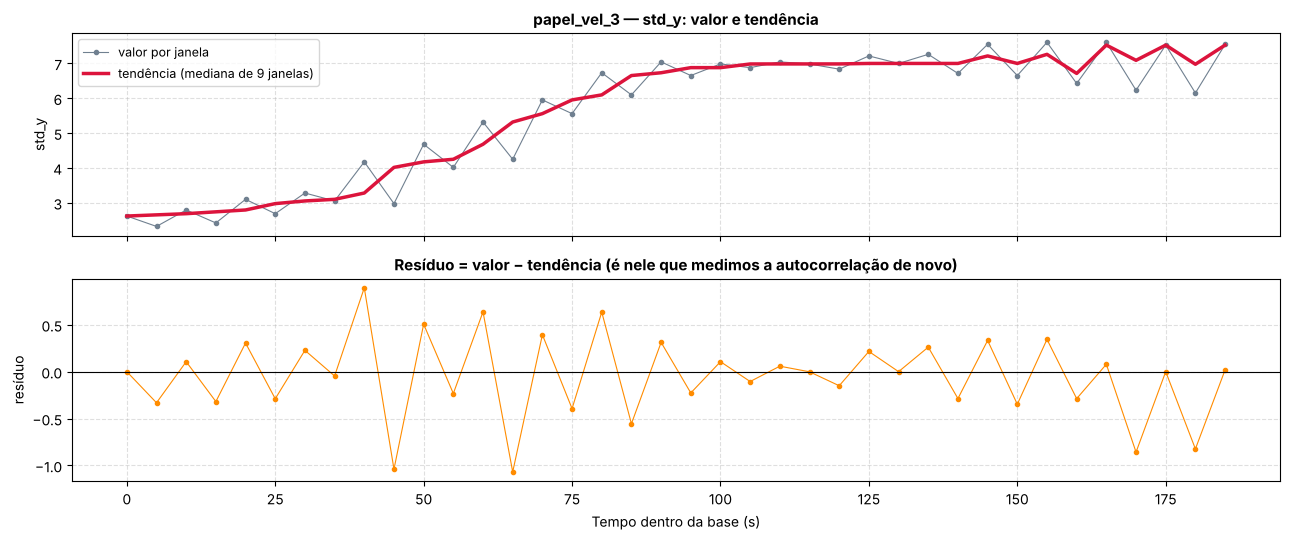

In [32]:
residuos, tendencias = remover_tendencia(features, COLUNAS_TODAS)
autocorrelacao_residuo = calcular_autocorrelacao_lag1(residuos, COLUNAS_TODAS)
display(comparar_autocorrelacao_com_e_sem_tendencia(autocorrelacao, autocorrelacao_residuo, features).round(2))

plotar_tendencia_e_residuo(features, residuos, tendencias, BASE_EXEMPLO_TENDENCIA, FEATURE_EXEMPLO_TENDENCIA)

In [33]:
def simular_autocorrelacao_do_ruido(n_janelas, janelas_tendencia=JANELAS_TENDENCIA, repeticoes=REPETICOES_SIMULACAO, semente=0):
    """Em séries de ruído puro com n_janelas pontos: desvio da autocorrelação de lag 1 (ruído) e a média depois
    de tirar a mediana móvel de janelas_tendencia pontos (viés). Devolve (ruido, vies)."""
    gerador = np.random.default_rng(semente)
    originais, sem_tendencia = [], []
    for _ in range(repeticoes):
        serie = pd.Series(gerador.standard_normal(n_janelas))
        originais.append(serie.autocorr(lag=1))
        residuo = serie - serie.rolling(janelas_tendencia, center=True, min_periods=1).median()
        sem_tendencia.append(residuo.autocorr(lag=1))
    return np.std(originais), np.mean(sem_tendencia)

In [34]:
n_tipico = int(features.groupby("base").size().median())
ruido_lag1, vies_tendencia = simular_autocorrelacao_do_ruido(n_tipico)
print(f"Com {n_tipico} janelas (a mediana das gravações), em ruído puro:")
print(f"  ruído da autocorrelação de lag 1 de uma feature: ±{ruido_lag1:.2f} (um desvio padrão)")
print(f"  viés de tirar a mediana móvel de {JANELAS_TENDENCIA} janelas: {vies_tendencia:.2f}")

Com 37 janelas (a mediana das gravações), em ruído puro:
  ruído da autocorrelação de lag 1 de uma feature: ±0.17 (um desvio padrão)
  viés de tirar a mediana móvel de 9 janelas: -0.12


### Conclusões do Passo 7

**Autocorrelação de lag 1 (7.1): o oposto da coleta anterior.**
* A mediana é **negativa em 26 das 27 gravações** (de −0,09 a −0,48). Na coleta anterior ela era **positiva** nas Vel 1 e 2 (de 0,16 a 0,63), por causa do aquecimento dentro da gravação.
* A única positiva é o **papel Vel 3 (+0,24)**, que tem a mudança de patamar do Notebook 01. O gráfico do 7.3 mostra: o `std_y` sobe de cerca de 2,6 para cerca de 7 m/s² entre cerca de 35 e 90 s e depois fica estável.
* Pela fórmula das janelas equivalentes (que conta autocorrelação negativa como zero), todas as gravações valem o seu número de janelas, menos o papel Vel 3 (cerca de 24 de 38).

**Ciclo lento (7.2 e 7.2.1): o mesmo mecanismo da coleta anterior.**
* **22 das 27 gravações** dão entre **210 e 236 voltas da hélice por ciclo**. Na coleta anterior eram cerca de 225, numa outra sessão: **o mecanismo da oscilação é movido pelo motor da hélice, e isso se repetiu**.
* As outras 5 pegaram uma fração do ciclo: 4 dão cerca de 111 a 114 voltas, ou seja, meio ciclo (N2 Vel 1, fita 1 g Vel 2 e Vel 3, N5 Vel 3), e o calço Vel 2 dá 76, cerca de um terço.
* **Períodos:** cerca de 16 a 18 s na Vel 1, 11,1 a 11,7 s na Vel 2 (o papel, mais lento, 13,6 s) e 8,9 a 9,5 s na Vel 3. São um pouco **mais curtos que na coleta anterior** (18 / 12 / 10 s), porque aqui o motor gira mais rápido (Vel 1 de 13,2 a 14,0 Hz, contra cerca de 12,4 Hz lá). É o que se espera se o ciclo durar sempre o mesmo número de voltas.

**Tendência ou ciclo? (7.3)**
* As réguas por simulação, com 37 janelas: ruído de **±0,17** na autocorrelação de uma feature e viés de **−0,12** ao tirar a mediana móvel de 9 janelas.
* Depois de tirar a tendência, a autocorrelação fica entre **−0,15 e −0,54**, quase toda abaixo do viés: **o que sobra é o ciclo da oscilação**. Como ela já era negativa antes, **não havia tendência a tirar**, exceto no papel Vel 3 (de +0,24 para −0,36).

**O que isso muda:**
1. **O risco do aquecimento dentro da gravação, que pesou na coleta anterior, praticamente não existe aqui.** O aquecimento está **entre** as gravações (Notebooks 01 e 02), e quem cuida dele é a comparação com os vizinhos e a avaliação por lote.
2. **Os p-valores continuam sendo guia.** Com autocorrelação negativa eles não ficam otimistas da mesma forma, mas as janelas também não são independentes (o ciclo).

### 7.4 — Até quantas janelas vai a dependência? (a guarda dos blocos do Notebook 05)

**O que buscamos:** no Notebook 05, cada gravação é cortada em **blocos de 30 s** (6 janelas) e alguns blocos ficam **trancados** para o teste final. Entre um bloco de treino e um bloco trancado vizinho fica uma **guarda** de `GUARDA_JANELAS` janela (5 s) que não é usada. A guarda existe para que uma janela do teste não seja "quase cópia" de uma janela do treino.

A guarda é suficiente se, **a partir da distância que ela cria**, as janelas já forem praticamente independentes. Com guarda de 1 janela, a janela de treino mais próxima de uma janela trancada fica a **2 janelas** de distância (lag 2).

**O que o código faz:** para cada gravação e cada feature, calcula a autocorrelação de lag 1 a 6 (de 5 a 30 s) e resume, por velocidade, a **mediana** e o **percentil 90** entre todas as features e gravações daquela velocidade.

**Como ler:**

* **Mediana perto de zero (dentro do ruído do 7.3) a partir do lag 2:** a guarda de 1 janela basta.
* **Valores negativos e depois positivos de novo:** é o ciclo da oscilação (uma janela forte, uma fraca, uma forte...). Isso não é vazamento: é a mesma variação que o modelo vai encontrar em dados novos.
* **Valores positivos que só caem devagar:** tendência; nesse caso a guarda deveria ser maior.

In [35]:
def autocorrelacao_por_lag(features, colunas, lags=LAGS):
    """Autocorrelação de cada feature em cada gravação, para cada lag. Tabela longa (base, velocidade, lag, feature, r)."""
    linhas = []
    for base, grupo in features.groupby("base", sort=False):
        grupo = grupo.sort_values("janela")
        for lag in lags:
            for coluna in colunas:
                linhas.append({"base": base, "velocidade": grupo["velocidade"].iloc[0], "lag": lag,
                               "feature": coluna, "r": grupo[coluna].autocorr(lag=lag)})
    return pd.DataFrame(linhas)


def resumir_por_lag(tabela):
    """Por velocidade e lag: mediana e percentil 90 da autocorrelação (entre features e gravações)."""
    return (tabela.groupby(["velocidade", "lag"])["r"]
            .agg(mediana="median", p90=lambda r: r.quantile(0.9))
            .unstack("velocidade"))


def plotar_autocorrelacao_por_lag(tabela, ruido, guarda=GUARDA_JANELAS):
    """Mediana (linha) e faixa dos percentis 10 a 90 da autocorrelação por lag, uma linha por velocidade."""
    fig, ax = plt.subplots(figsize=(10, 4.5))
    cores = {1: "dodgerblue", 2: "crimson", 3: "limegreen"}
    for velocidade, parte in tabela.groupby("velocidade"):
        resumo = parte.groupby("lag")["r"].quantile([0.1, 0.5, 0.9]).unstack()
        ax.fill_between(resumo.index, resumo[0.1], resumo[0.9], color=cores.get(velocidade, "gray"), alpha=0.12)
        ax.plot(resumo.index, resumo[0.5], marker="o", color=cores.get(velocidade, "gray"), label=f"Vel {velocidade} (mediana)")
    ax.axhspan(-ruido, ruido, color="gold", alpha=0.25, label=f"ruído de uma feature (±{ruido:.2f})")
    ax.axhline(0, color="black", linewidth=0.8)
    ax.axvline(guarda + 1, color="black", linestyle="--", label=f"menor distância treino × trancado (lag {guarda + 1})")
    ax.set_xlabel(f"distância entre as janelas (lag, em janelas de {JANELA_S} s)")
    ax.set_ylabel("autocorrelação")
    ax.legend(fontsize=9)
    ax.set_title("Autocorrelação por distância (faixas = percentis 10 a 90 entre features e gravações)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

mediana               p90            
velocidade       1     2     3     1     2     3
lag                                             
1            -0.21 -0.24 -0.30  0.04  0.21  0.18
2            -0.25  0.32  0.55  0.10  0.59  0.85
3             0.32 -0.12 -0.27  0.64  0.28  0.14
4             0.05 -0.05  0.33  0.35  0.24  0.65
5            -0.28  0.15 -0.21  0.14  0.52  0.12
6            -0.05 -0.19  0.13  0.32  0.13  0.47

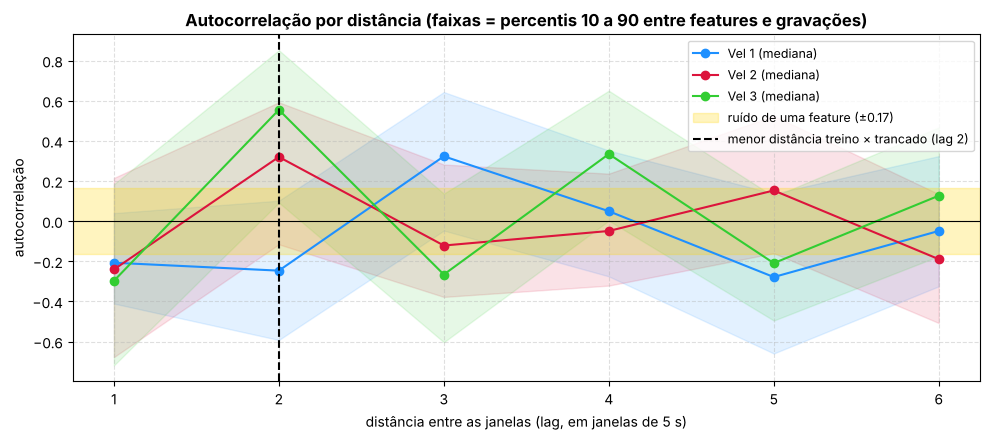

In [36]:
autocorrelacao_lags = autocorrelacao_por_lag(features, COLUNAS_TODAS)
display(resumir_por_lag(autocorrelacao_lags).round(2))
plotar_autocorrelacao_por_lag(autocorrelacao_lags, ruido_lag1)

### Conclusões do Passo 7.4

| Lag (janelas) | Vel 1 | Vel 2 | Vel 3 |
| --- | --- | --- | --- |
| 1 | −0,21 | −0,24 | −0,30 |
| 2 | −0,25 | **+0,32** | **+0,55** |
| 3 | **+0,32** | −0,12 | −0,27 |
| 4 | +0,05 | −0,05 | **+0,33** |
| 5 | −0,28 | +0,15 | −0,21 |
| 6 | −0,05 | −0,19 | +0,13 |

(mediana entre features e gravações)

* **A dependência não diminui com a distância: ela vai e volta.** É o ciclo da oscilação visto em janelas.
  * **Vel 3:** o ciclo dura cerca de 9,5 s, ou quase 2 janelas, então as janelas a 2 e 4 de distância ficam parecidas (+0,55 e +0,33), e as a 1 e 3, opostas.
  * **Vel 2:** o ciclo dura cerca de 11,3 s (2,3 janelas): pico em lag 2 (+0,32).
  * **Vel 1:** o ciclo dura cerca de 17 s (3,4 janelas): pico em lag 3 (+0,32).
* **A guarda de 1 janela é suficiente.** O que ela evita é uma dependência que **cai com a distância** (tendência, memória curta), e essa não aparece: em lag 1 a mediana é negativa nas três velocidades. A semelhança periódica **volta a cada ciclo** em qualquer ponto da gravação, então uma guarda maior não a eliminaria (na Vel 3, lag 4 ainda tem +0,33). Ela não é vazamento: é a mesma variação que o modelo vai encontrar em dados novos.
* **Os blocos de 30 s são uma boa escolha:** cada bloco contém de 1,7 ciclo (Vel 1) a mais de 3 ciclos (Vel 3), então **todo bloco vê todas as fases da oscilação**. Um bloco trancado não fica preso a uma fase só do ciclo.
* **Decisão:** manter o desenho aprovado para o Notebook 05 (blocos de 30 s, guarda de 1 janela, 2 blocos trancados por gravação).

## Passo 8 — Transformação logarítmica

**O que buscamos:** descobrir se trocar cada valor pelo seu **logaritmo natural** deixa as features **mais próximas da normal**.

**Por que o log pode ajudar.** Features como desvio padrão, pico e amplitudes da FFT são sempre positivas e costumam ter **cauda comprida para a direita**: a maioria das janelas tem valores parecidos e algumas poucas têm valores bem maiores. O log **comprime os valores grandes** e **estica os pequenos**, deixando essa distribuição mais simétrica. É muito comum em vibração, porque efeitos de falha costumam ser **multiplicativos** (a vibração dobra) e o log transforma multiplicação em soma.

**O que o código faz:**

1. Separa as features que **aceitam log** (todas as janelas maiores que zero) das que não aceitam.
2. Aplica `np.log` nas que aceitam e **refaz os mesmos testes** (Shapiro-Wilk com BH e assimetria).
3. Compara **antes e depois**, nas **mesmas features**, para a comparação ser justa.

**Atenção a dois pontos:**

* O log **muda a escala**: depois dele, "diferença" passa a significar "razão". Isso é bom para K-Means (distância mais justa entre features de tamanhos diferentes), mas os valores deixam de estar em m/s².
* O log **não tem parâmetro para aprender**, então não causa vazamento de dados. Mas, ao usar o modelo em dados novos, o mesmo log precisa ser aplicado.

In [37]:
def separar_features_para_log(features, colunas):
    """Divide as colunas em: estritamente positivas (aceitam log) e as demais (têm zero ou valor negativo)."""
    positivas = [c for c in colunas if (features[c] > 0).all()]
    demais = [c for c in colunas if c not in positivas]
    return positivas, demais


def aplicar_log(features, colunas):
    """Devolve uma cópia da tabela com o logaritmo natural nas colunas dadas."""
    nova = features.copy()
    nova[colunas] = np.log(nova[colunas])
    return nova

In [38]:
COLUNAS_COM_LOG, COLUNAS_SEM_LOG = separar_features_para_log(features, COLUNAS_TODAS)
print(f"Recebem log: {len(COLUNAS_COM_LOG)} features (todas as janelas estritamente positivas).")
print(f"Não recebem log: {len(COLUNAS_SEM_LOG)} features -> {COLUNAS_SEM_LOG}")

features_log = aplicar_log(features, COLUNAS_COM_LOG)
resultado_log = testar_normalidade(features_log, COLUNAS_COM_LOG)
resultado_original_comparavel = resultado_original[resultado_original["feature"].isin(COLUNAS_COM_LOG)]

Recebem log: 106 features (todas as janelas estritamente positivas).
Não recebem log: 3 features -> ['kurt_x', 'kurt_y', 'kurt_z']


### 8.1 — Antes e depois do log, em números

**O que buscamos:** saber se o log **aproximou as features da normal**, olhando o mesmo teste (Shapiro-Wilk com correção BH) e a mesma assimetria nas **mesmas features**, antes e depois.

* **% normais (q BH):** sobe se o log ajudou.
* **mediana |assimetria|:** cai se o log reduziu a "cauda comprida".

In [39]:
def comparar_antes_e_depois(resultado_antes, resultado_depois, rotulo_depois="depois do log"):
    """Tabela lado a lado (por grupo) do resumo antes e depois da transformação."""
    antes = resumir_normalidade(resultado_antes)[["% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]]
    depois = resumir_normalidade(resultado_depois)[["% normais (q BH)", "% tortas (|assim.| > limite)", "mediana |assimetria|"]]
    return pd.concat({"antes": antes, rotulo_depois: depois}, axis=1).swaplevel(axis=1).sort_index(axis=1)


def comparar_por_tipo(resultado_antes, resultado_depois, rotulo_depois="depois do log"):
    """Resumo antes e depois, juntando todos os grupos, separado por tipo de feature."""
    linhas = {}
    for nome, resultado in (("antes", resultado_antes), (rotulo_depois, resultado_depois)):
        validos = resultado[resultado["p_bruto"].notna()]
        por_tipo = validos.groupby("tipo").apply(lambda g: pd.Series({
            "% normais (q BH)": 100 * (~g["nao_normal_bh"]).mean(),
            "% tortas": 100 * g["torta"].mean(),
            "mediana |assimetria|": g["assimetria"].abs().median(),
            "W mediano": g["W"].median(),
        }), include_groups=False)
        linhas[nome] = por_tipo
    return pd.concat(linhas, axis=1).swaplevel(axis=1).sort_index(axis=1)

In [40]:
display(comparar_antes_e_depois(resultado_original_comparavel, resultado_log).round(1))
print("Resumo por tipo de feature (todos os grupos juntos):")
display(comparar_por_tipo(resultado_original_comparavel, resultado_log).round(2))

% normais (q BH)                \
                                  antes depois do log   
gravacao    velocidade                                  
1. N1       1                      70.8          92.5   
            2                      66.0          73.6   
            3                      74.5          89.6   
2. calco    1                      60.4          90.6   
            2                      68.9          81.1   
            3                      48.1          70.8   
3. N2       1                      69.8          91.5   
            2                      50.9          87.7   
            3                      72.6          97.2   
4. fita_1g  1                      73.6          78.3   
            2                      51.9          62.3   
            3                      43.4          79.2   
5. N3       1                      60.4          79.2   
            2                      49.1          89.6   
            3                      63.2          77.4   
6. fita_05g 1                      63.2          73.6   
            2                      32.1          68.9   
            3                      25.5          95.3   
7. N4       1                      63.2          77.4   
            2                      45.3          69.8   
            3                      63.2          86.8   
8. papel    1                      56.6          74.5   
            2                      49.1          69.8   
            3                      26.4          72.6   
9. N5       1                      55.7          80.2   
            2                      64.2          89.6   
            3                      59.4          84.9   

                       % tortas (|assim.| > limite)                \
                                              antes depois do log   
gravacao    velocidade                                              
1. N1       1                                  16.0           8.5   
            2                                  11.3          14.2   
            3                                  13.2           6.6   
2. calco    1                                  12.3           4.7   
            2                                  19.8           7.5   
            3                                  10.4           3.8   
3. N2       1                                  22.6           5.7   
            2                                  22.6           3.8   
            3                                  17.0           1.9   
4. fita_1g  1                                  12.3           9.4   
            2                                  34.0          17.9   
            3                                  42.5          18.9   
5. N3       1                                  17.0           7.5   
            2                                  17.9           3.8   
            3                                  15.1           5.7   
6. fita_05g 1                                  15.1          11.3   
            2                                  34.0           8.5   
            3                                  31.1           5.7   
7. N4       1                                  14.2           9.4   
            2                                  27.4           7.5   
            3                                  18.9           4.7   
8. papel    1                                  25.5          14.2   
            2                                  26.4          21.7   
            3                                  34.0          10.4   
9. N5       1                                  15.1           9.4   
            2                                  18.9           6.6   
            3                                  13.2           3.8   

                       mediana |assimetria|                
                                      antes depois do log  
gravacao    velocidade                                     
1. N1       1                           0.4           0.3  
 

Resumo por tipo de feature (todos os grupos juntos):


% normais (q BH)               % tortas               W mediano  \
                   antes depois do log    antes depois do log     antes   
tipo                                                                      
FFT                55.72         82.47    23.46          8.44      0.94   
rotação            58.89         73.33     4.07          7.78      0.94   
tempo              65.43         69.75     6.17         12.96      0.95   

                      mediana |assimetria|                
        depois do log                antes depois do log  
tipo                                                      
FFT              0.96                 0.59          0.36  
rotação          0.95                 0.37          0.32  
tempo            0.94                 0.29          0.35

### 8.2 — Cada feature, antes e depois

**O que buscamos:** ver o efeito do log **feature por feature**, em vez de só a média.

Cada ponto é uma feature num grupo. O eixo **x** é o W antes do log e o eixo **y** é o W depois.

* **Ponto acima da diagonal:** o log deixou a feature **mais normal**.
* **Ponto abaixo da diagonal:** o log **piorou**.
* **Ponto sobre a diagonal:** não mudou.

In [41]:
def plotar_w_antes_e_depois(resultado_antes, resultado_depois, titulo):
    """Dispersão do W antes (x) e depois (y) do log, um ponto por feature e grupo."""
    chaves = ["gravacao", "velocidade", "feature"]
    juntos = resultado_antes.merge(resultado_depois, on=chaves, suffixes=("_antes", "_depois"))
    juntos = juntos[juntos["W_antes"].notna() & juntos["W_depois"].notna()]
    fig, ax = plt.subplots(figsize=(7.5, 7))
    for tipo, cor in CORES_TIPO.items():
        parte = juntos[juntos["tipo_antes"] == tipo]
        ax.scatter(parte["W_antes"], parte["W_depois"], s=14, alpha=0.5, color=cor, label=tipo)
    limites = [min(juntos["W_antes"].min(), juntos["W_depois"].min()) - 0.01, 1.005]
    ax.plot(limites, limites, color="black", linewidth=1)
    ax.set_xlim(limites)
    ax.set_ylim(limites)
    ax.set_xlabel("W antes do log")
    ax.set_ylabel("W depois do log")
    ax.legend(title="tipo de feature")
    melhoraram = 100 * (juntos["W_depois"] > juntos["W_antes"]).mean()
    ax.set_title(f"{titulo}\n{melhoraram:.0f}% dos pontos ficaram acima da diagonal", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.show()

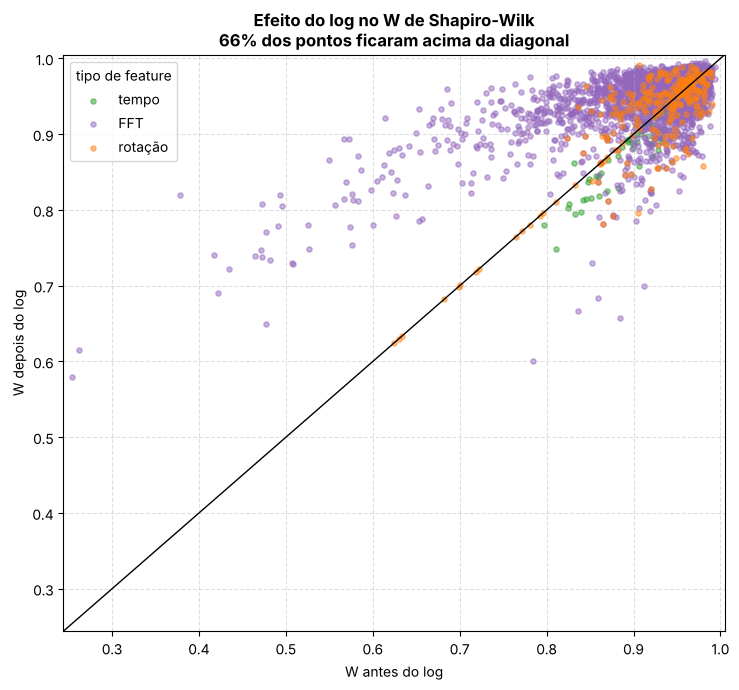

In [42]:
plotar_w_antes_e_depois(resultado_original_comparavel, resultado_log, "Efeito do log no W de Shapiro-Wilk")

### 8.3 — Histograma e QQ-plot, antes e depois

**O que buscamos:** ver com os próprios olhos o que o log fez nas features de exemplo. Para cada feature, **à esquerda** o formato original e **à direita** o formato depois do log, sempre com a curva normal por cima e o QQ-plot ao lado.

Se os pontos do QQ-plot ficam mais perto da reta depois do log, ele ajudou.

In [43]:
def plotar_antes_e_depois_do_log(features, features_log, condicao, velocidade, colunas_exemplo):
    """Por feature, de um grupo: histograma e QQ-plot antes (esquerda) e depois do log (direita)."""
    fig, axs = plt.subplots(len(colunas_exemplo), 4, figsize=(18, 3.3 * len(colunas_exemplo)), squeeze=False)
    for i, coluna in enumerate(colunas_exemplo):
        for deslocamento, tabela, rotulo in ((0, features, "antes"), (2, features_log, "depois do log")):
            valores = selecionar_janelas(tabela, [condicao], velocidade)[coluna].to_numpy()
            ax_hist, ax_qq = axs[i, deslocamento], axs[i, deslocamento + 1]
            ax_hist.hist(valores, bins=15, density=True, color="slategray", alpha=0.6)
            eixo_x = np.linspace(valores.min(), valores.max(), 200)
            ax_hist.plot(eixo_x, norm.pdf(eixo_x, valores.mean(), valores.std(ddof=1)), color="black", linewidth=1.5)
            p_valor = shapiro(valores)[1]
            ax_hist.set_title(f"{coluna} — {rotulo}\nShapiro p = {p_valor:.3g}; assimetria = {skew(valores, bias=False):.2f}", fontsize=9, fontweight="bold")
            padronizados = np.sort((valores - valores.mean()) / valores.std(ddof=1))
            teoricos = norm.ppf((np.arange(1, len(valores) + 1) - 0.5) / len(valores))
            ax_qq.scatter(teoricos, padronizados, s=12, color="slategray", alpha=0.8)
            ax_qq.plot([-3.5, 3.5], [-3.5, 3.5], color="black", linewidth=1)
            ax_qq.set_title("QQ-plot", fontsize=9, fontweight="bold")
    fig.suptitle(f"{condicao} — Vel {velocidade}", fontsize=13, fontweight="bold")
    plt.tight_layout(rect=[0, 0, 1, 0.97])
    plt.show()

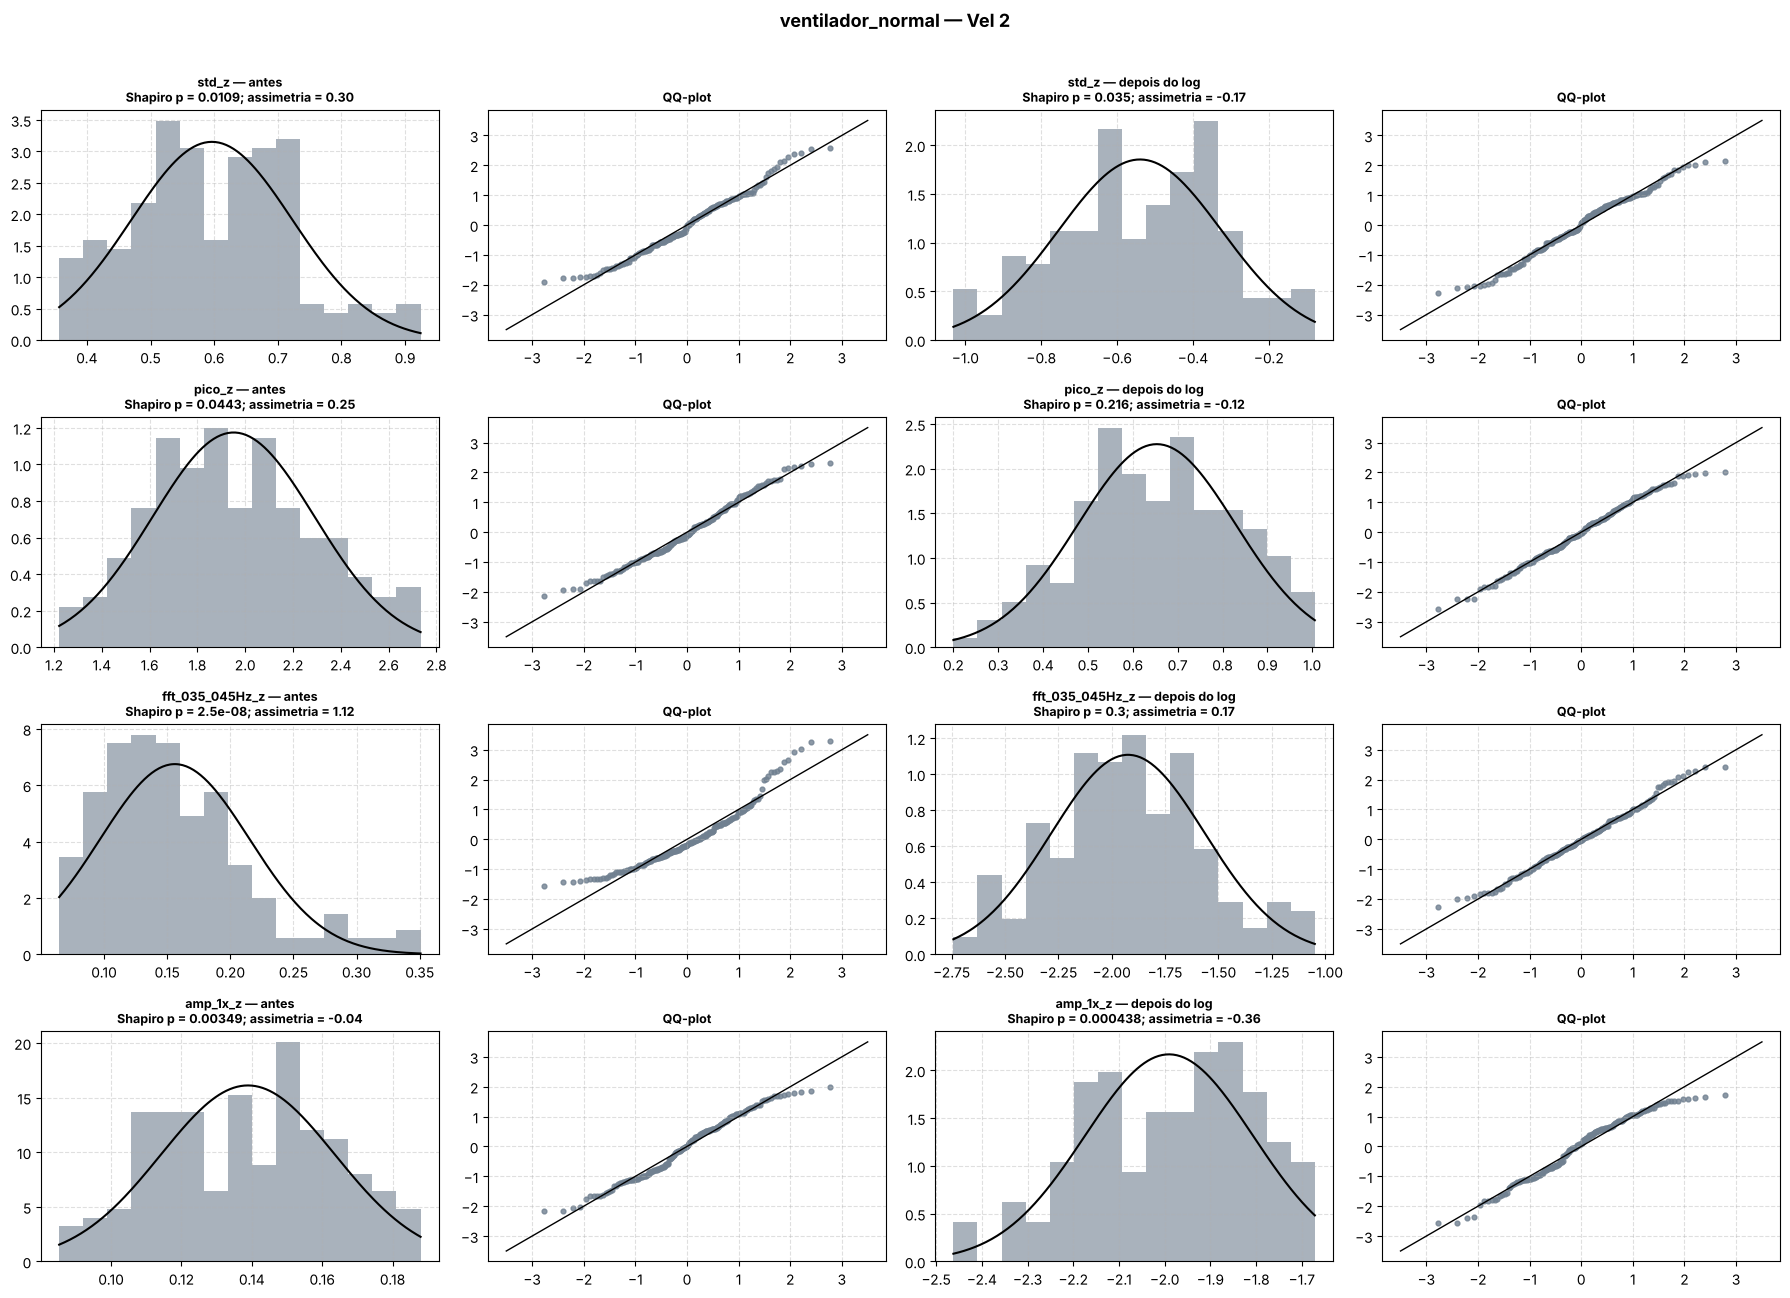

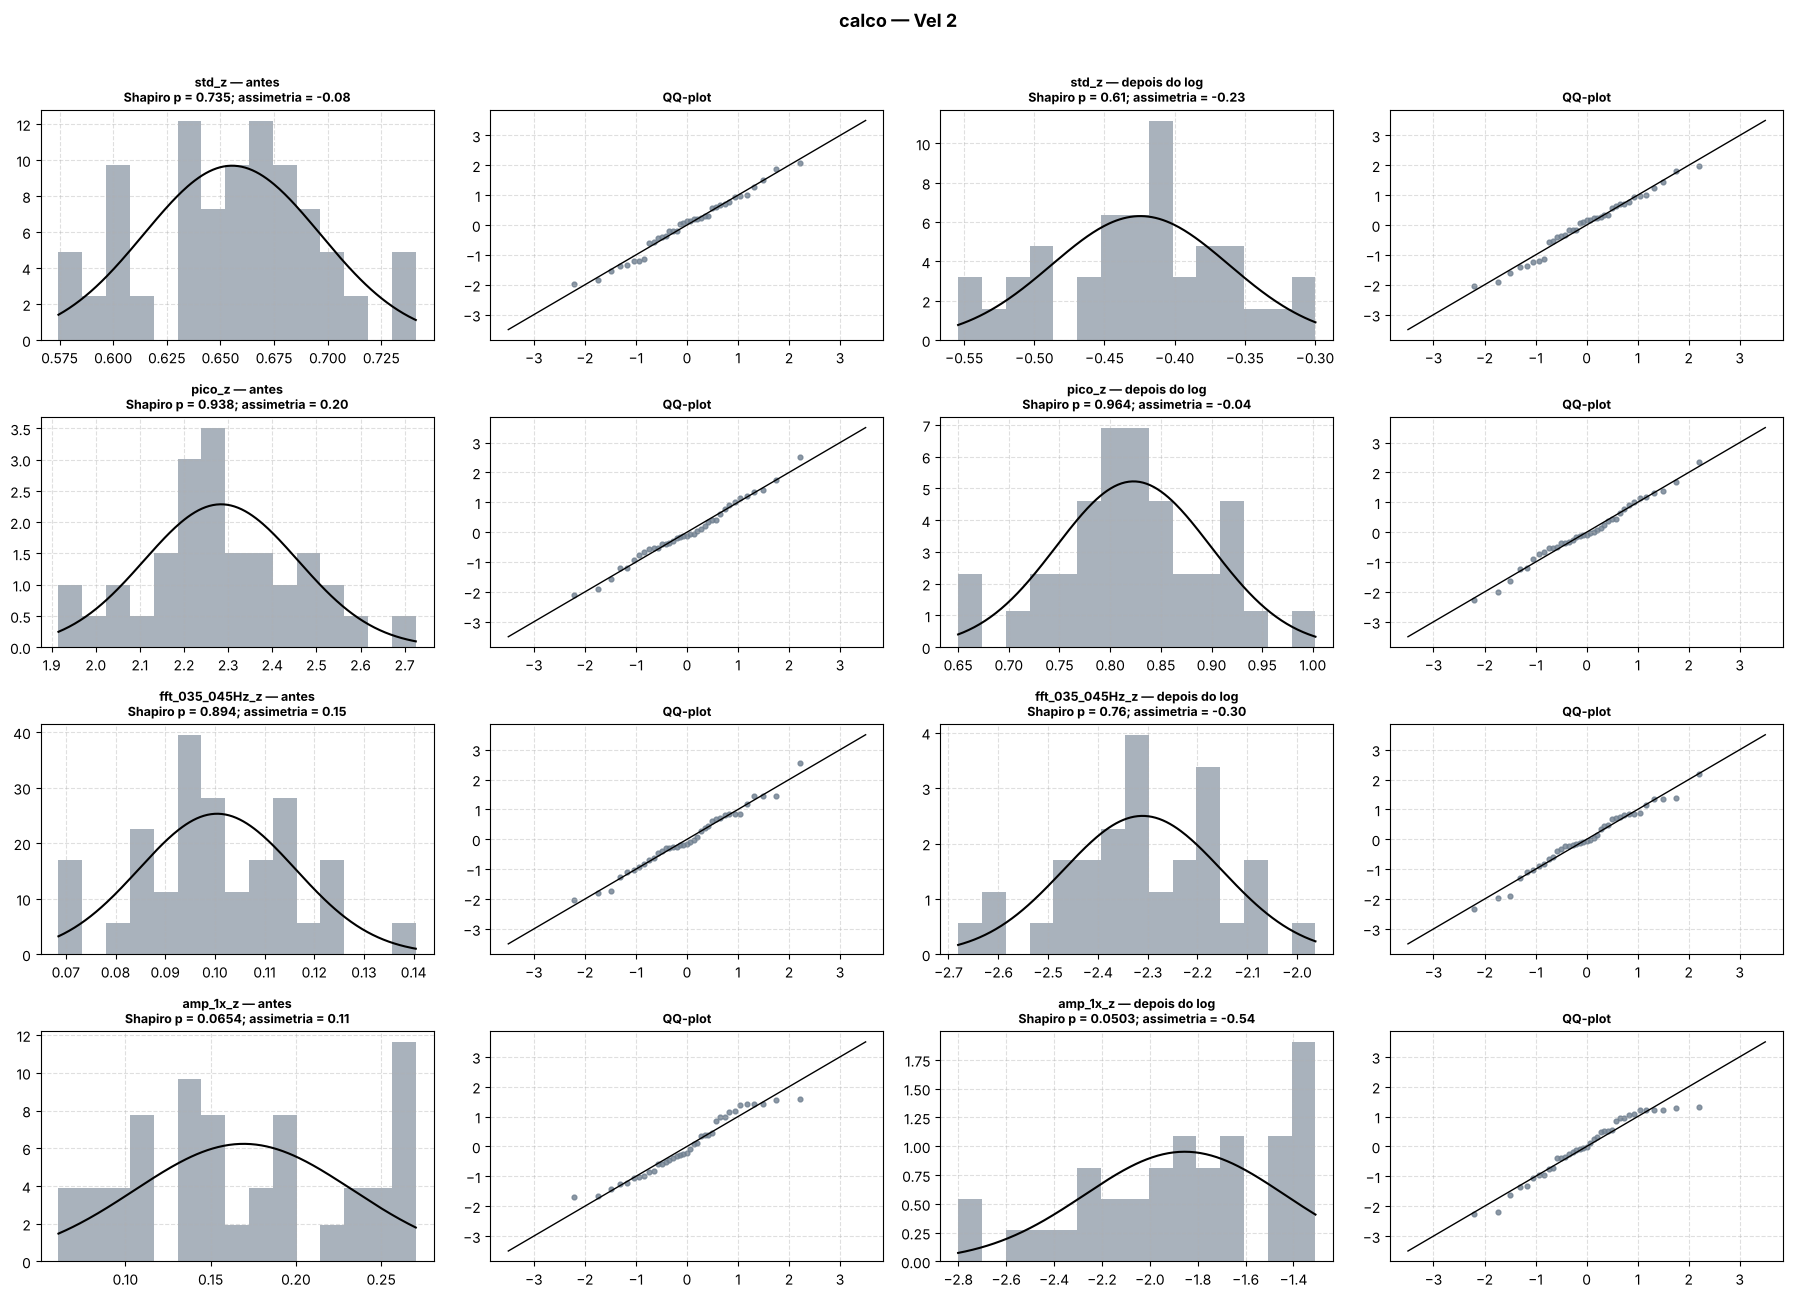

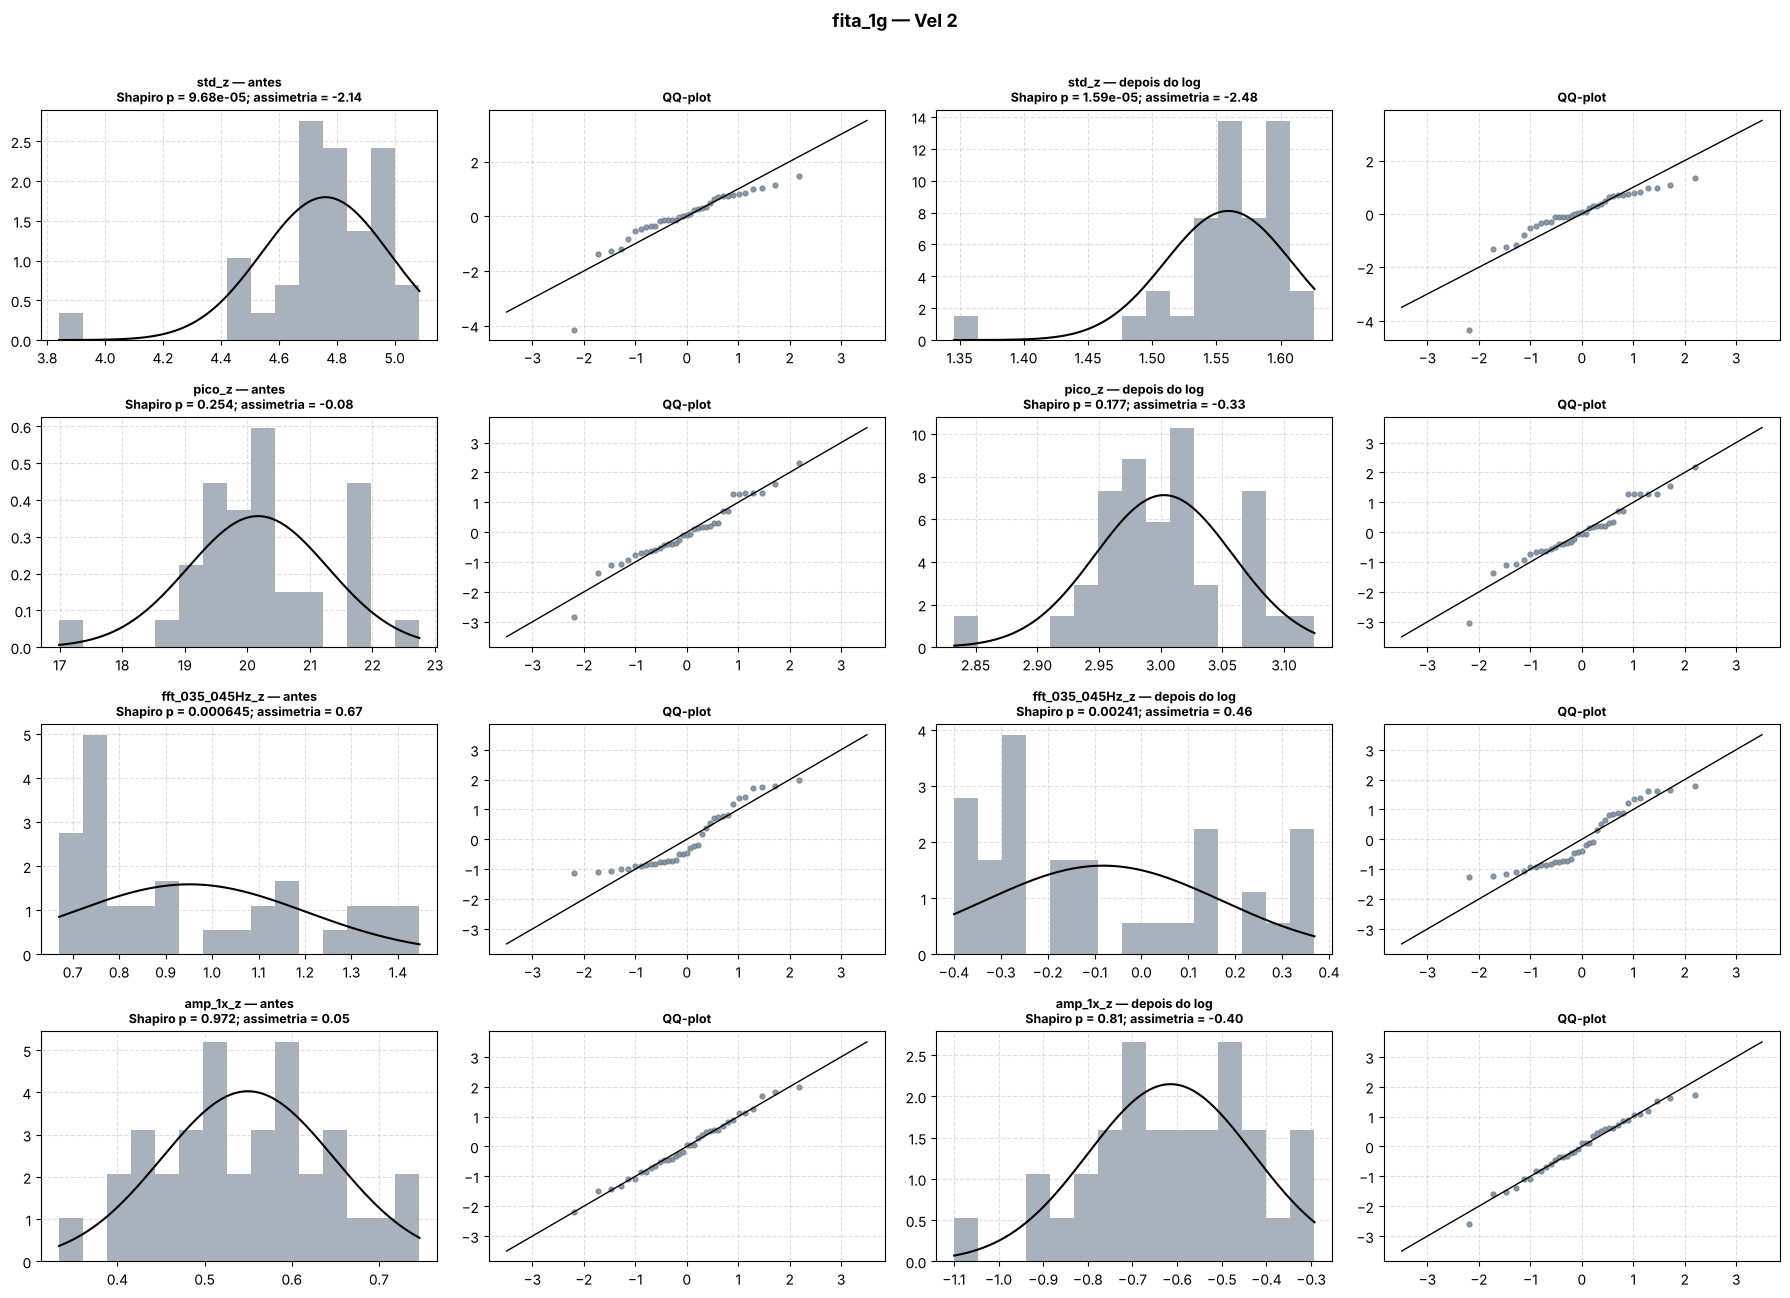

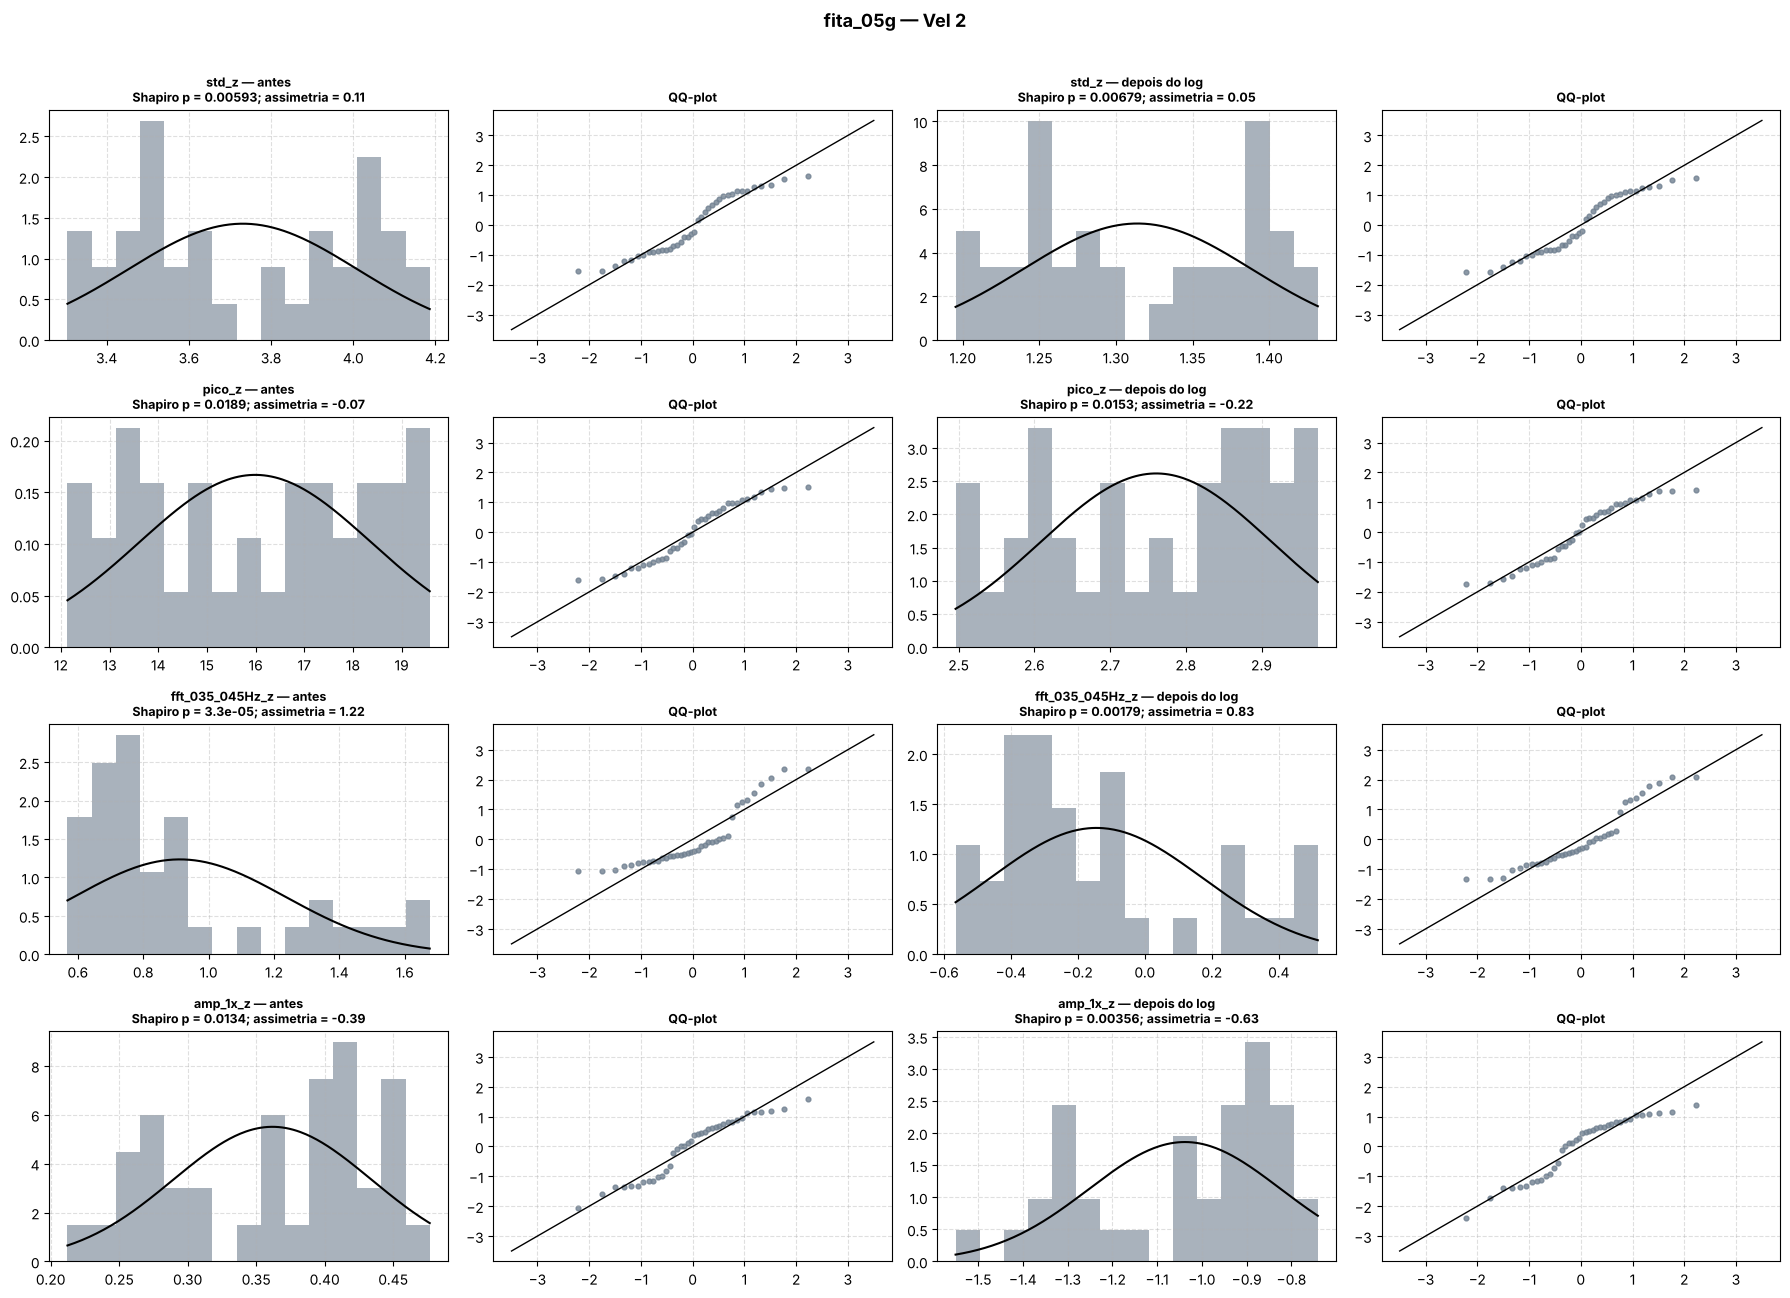

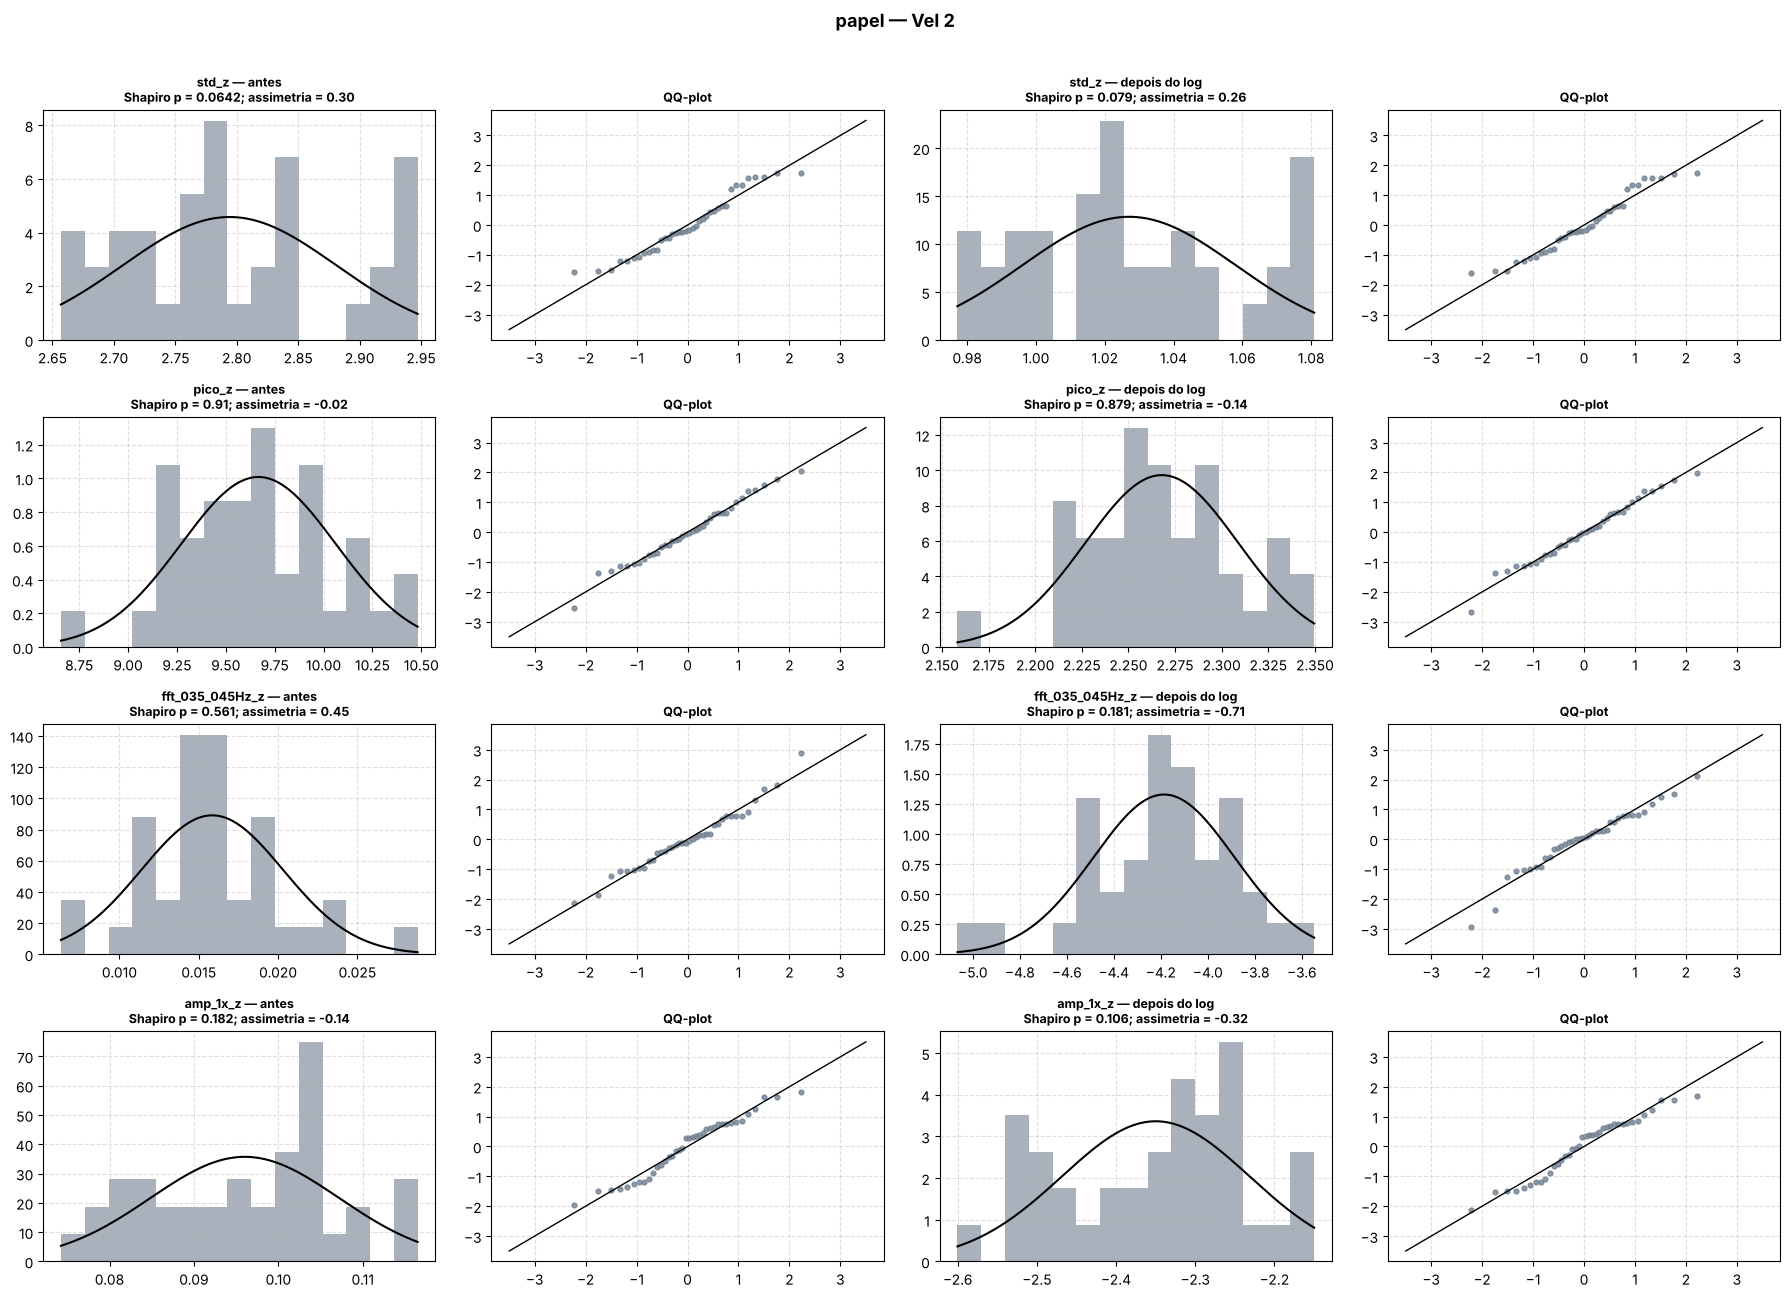

In [44]:
EXEMPLOS_COM_LOG = [c for c in FEATURES_EXEMPLO if c in COLUNAS_COM_LOG]

for condicao in CONDICOES_REFERENCIA + condicoes_comparadas:
    plotar_antes_e_depois_do_log(features, features_log, condicao, VELOCIDADE_EXEMPLO, EXEMPLOS_COM_LOG)

### Conclusões do Passo 8

**Por tipo, todas as gravações juntas (nas 106 features que aceitam log):**

| Tipo | % normais (antes → depois) | % tortas (antes → depois) | mediana \|assimetria\| (antes → depois) |
| --- | --- | --- | --- |
| FFT | 55,7 → **82,5** | 23,5 → **8,4** | 0,59 → **0,36** |
| Rotação | 58,9 → 73,3 | 4,1 → 7,8 | 0,37 → 0,32 |
| Tempo (sem curtose) | 65,4 → 69,8 | 6,2 → 13,0 | 0,29 → 0,35 |

* **FFT: o log ajuda muito, de novo.** É o terceiro conjunto de dados (antigos, NOVOS_DADOS e NOVOS_2.0) em que isso acontece: as faixas da FFT têm cauda comprida à direita, e o log a corrige.
* **Rotação:** efeito pequeno. Na coleta anterior o log piorava bastante a assimetria (tortas de 22% para 39%); aqui fica de 4% para 8%.
* **Tempo (`std` e `pico`):** o log deixa um pouco **mais torto** (tortas de 6% para 13%; assimetria de 0,29 para 0,35). Essas features já eram quase simétricas dentro de cada gravação, e o log cria uma cauda à esquerda.
* **Por gravação:** o log melhora a porcentagem de normais em todas as 27 gravações. Os maiores ganhos são justamente nas que eram as piores: fita 0,5 g Vel 3 (de 25% para 95%) e papel Vel 3 (de 26% para 73%).

## Passo 9 — Features que não aceitam log: a curtose

**O que buscamos:** a curtose (`kurt_x`, `kurt_y`, `kurt_z`) pode ser **negativa**, e o log não existe para valores negativos ou zero. Testamos uma alternativa que aceita qualquer número: a transformação **Yeo-Johnson**.

**Como funciona:** ela escolhe, para cada conjunto de dados, o **melhor "grau de esticamento"** (o parâmetro λ) para deixar a distribuição o mais simétrica possível. É uma família de transformações, e o log é um caso particular.

**Cuidado importante:** o λ é **aprendido dos dados**. Aqui ele é ajustado dentro de cada gravação **só para comparar o formato**, e isso **não pode ser usado como pré-processamento de modelo**: num modelo, o λ deve ser ajustado só no conjunto de treino, e aplicado igual no teste (senão há vazamento de dados). Cada grupo tem um λ diferente, então os valores transformados de grupos diferentes não são comparáveis entre si.

In [45]:
def transformar_com_yeo_johnson_por_grupo(features, colunas):
    """Yeo-Johnson ajustado separadamente em cada gravação. Só para comparação descritiva."""
    nova = features.copy()
    for _, indices in features.groupby(["gravacao", "velocidade"]).groups.items():
        for coluna in colunas:
            nova.loc[indices, coluna] = yeojohnson(features.loc[indices, coluna].to_numpy())[0]
    return nova

In [46]:
features_yj = transformar_com_yeo_johnson_por_grupo(features, COLUNAS_SEM_LOG)
resultado_yj = testar_normalidade(features_yj, COLUNAS_SEM_LOG)
resultado_sem_log_original = resultado_original[resultado_original["feature"].isin(COLUNAS_SEM_LOG)]

print("Features sem log: antes e depois do Yeo-Johnson (por tipo, todos os grupos juntos)")
display(comparar_por_tipo(resultado_sem_log_original, resultado_yj, "depois do Yeo-Johnson").round(2))

Features sem log: antes e depois do Yeo-Johnson (por tipo, todos os grupos juntos)


% normais (q BH)                       % tortas                        \
                 antes depois do Yeo-Johnson    antes depois do Yeo-Johnson   
tipo                                                                          
tempo             67.9                 79.01     6.17                   0.0   

      W mediano                       mediana |assimetria|  \
          antes depois do Yeo-Johnson                antes   
tipo                                                         
tempo      0.94                  0.96                 0.44   

                             
      depois do Yeo-Johnson  
tipo                         
tempo                  0.06

### Conclusões do Passo 9

* **A curtose** parece normal em 68% dos casos e é pouco torta (6% tortas, mediana de |assimetria| de 0,44). Nos NOVOS_DADOS ela era mais torta (0,64).
* **O Yeo-Johnson** sobe para 79% de normais, com 0% de tortas e assimetria de 0,06.
* **A decisão continua sendo não transformar a curtose**, pelos mesmos motivos da coleta anterior: o Yeo-Johnson aprende um parâmetro (λ) e só pode entrar **dentro do Pipeline**, ajustado no treino; e o ganho de formato não garante ganho no modelo. Fica como variação opcional no Notebook 05.

## Resumo e decisões para os Notebooks 04 e 05

**O que buscamos:** uma tabela única, por tipo de feature, com o estado das distribuições **antes** e **depois do log**, e as decisões que levamos para o K-Means.

Como ler a tabela: **% normais** deve subir e **mediana |assimetria|** deve cair se o log ajudar. As duas medidas têm de apontar para o mesmo lado para a conclusão ser firme.

In [47]:
def montar_tabela_de_decisoes(resultado_antes, resultado_depois):
    """Resumo final: por tipo de feature, como estão as distribuições antes e depois do log."""
    tabela = comparar_por_tipo(resultado_antes, resultado_depois)
    return tabela[[("% normais (q BH)", "antes"), ("% normais (q BH)", "depois do log"),
                   ("mediana |assimetria|", "antes"), ("mediana |assimetria|", "depois do log")]]

In [48]:
display(montar_tabela_de_decisoes(resultado_original_comparavel, resultado_log).round(2))

% normais (q BH)               mediana |assimetria|              
                   antes depois do log                antes depois do log
tipo                                                                     
FFT                55.72         82.47                 0.59          0.36
rotação            58.89         73.33                 0.37          0.32
tempo              65.43         69.75                 0.29          0.35

### Decisões para os Notebooks 04 e 05 (NOVOS_2.0)

**Respostas diretas às perguntas do início:**

1. **As features são normais?** Em parte: cerca de 57% parecem normais dentro de cada gravação, mas com só cerca de 37 janelas o teste é pouco sensível. A **assimetria** é a medida mais confiável aqui: 20% dos testes são claramente tortos, quase todos em FFT.
2. **Juntar os 5 normais muda o formato?** Sim: a mistura fica mais larga e torta (assimetria mediana de até 0,95 na Vel 2), porque cada lote ocupa um lugar diferente (aquecimento entre lotes).
3. **O desvio é grave?** Para a maioria, não: 694 de 2.943 testes rejeitam sem a feature ser torta. As 4 janelas atípicas não pesam.
4. **As janelas são independentes?** Não, mas a dependência é o **ciclo da oscilação** (autocorrelação negativa em lag 1, mediana negativa em 26 das 27 gravações), **não tendência**. O ciclo continua durando cerca de **225 voltas da hélice**, como na coleta anterior.
5. **A guarda de 5 s basta?** Sim. A dependência vai e volta com o ciclo, sem cair com a distância; blocos de 30 s veem todas as fases do ciclo.
6. **O log ajuda?** Nas FFT, muito (tortas de 23% para 8%). Em rotação e tempo, o efeito é pequeno (em tempo, um pouco para pior).

| Decisão | Por quê |
| --- | --- |
| **Não exigir normalidade** | O K-Means e os classificadores usam distância ou cortes; o que pesa é a escala e os extremos. |
| **Log em todas as features menos as curtoses** (decisão vigente, mantida) | Ganho grande nas FFT, que são 90 das 109 features; em tempo e rotação o efeito é pequeno. A variação "log só nas FFT" continua anotada para o Notebook 05. |
| **Curtose sem transformação** | O Yeo-Johnson exigiria ajustar λ no treino; opcional dentro do Pipeline. |
| **Ordem: log primeiro, scaler depois** | O log não tem parâmetro; o scaler tem, e é ajustado só no treino. |
| **Manter todas as janelas** | Só 4 atípicas, sem efeito no resultado. |
| **Blocos de 30 s, guarda de 1 janela (Notebook 05)** | Confirmados pelo Passo 7.4. |

**Cuidados para os próximos notebooks:**

* **`f1x_hz` é discreto** (passos de 0,2 Hz, de 2 a 7 valores por gravação). Em distâncias e cortes isso funciona, mas a rotação "pula" de um valor para outro em vez de variar suavemente. Junto com o que o Notebook 02 mostrou (ela carrega o aquecimento e o freio das anomalias), é mais um motivo para o Notebook 05 testar o resultado sem ela.
* **K-Means (Notebook 04):** como o normal muda de lote para lote, **pinte as janelas pelo lote** (N1 a N5). Se um cluster juntar "N1 e N2" e outro "N4 e N5", o K-Means separou momento da sessão, não condição.
* **Notebook 06:** o normal com todos os lotes juntos não forma um sino só (Passo 5.2). Vale preferir detectores que não supõem um formato e avaliar sempre deixando um lote ou uma sessão inteira de fora.

**Perguntas para o grupo:** as mesmas de antes. Em qual velocidade foram cronometrados os 12 s do ciclo? Os dados desta sessão indicam cerca de 17 s na Vel 1, 11 s na Vel 2 e 9,5 s na Vel 3.

## O que conferir antes de seguir para o Notebook 04

* [ ] **Passo 2:** as 27 gravações e o número de janelas (33 a 43) fazem sentido.
* [ ] **Passo 5:** você entendeu por que as porcentagens de "normais" não se comparam com as da coleta anterior (cerca de 37 janelas contra 125) e por que o `f1x_hz` sempre "falha" no teste (valores discretos).
* [ ] **Passo 5.2:** você viu que juntar os 5 normais cria uma distribuição larga e com vários montes, e o que isso significa para o Notebook 06.
* [ ] **Passo 7:** a autocorrelação é negativa (ciclo), não positiva (tendência); o ciclo continua durando cerca de 225 voltas da hélice.
* [ ] **Passo 7.4:** a guarda de 1 janela e os blocos de 30 s do Notebook 05 estão confirmados.
* [ ] **Passo 8:** o resultado do log está anotado: ganho grande nas FFT, pequeno no resto.

**Próximo passo:** Notebook 04, **K-Means com scaler local**, com as janelas pintadas por lote e as decisões acima.